# Análise de Acromegalia - SIASUS

Análise de dados de APAC Medicamentos (AM) e Produção Ambulatorial (PA) do SIASUS para acromegalia.


In [1]:
# Função para gerar nome de arquivo com data atual
# Terceira revisão: todos os artefatos corrigidos são salvos em resultados/third_review/,
# com nomes de arquivos, abas, colunas e valores em inglês (func/translation_en.R)
source("func/translation_en.R")
pasta_resultados <- "../resultados/third_review/"
if (!dir.exists(pasta_resultados)) {
  dir.create(pasta_resultados, recursive = TRUE)
}

gerar_nome_arquivo <- function(indicador) {
  data_atual <- format(Sys.Date(), "%Y%m%d")
  return(paste0(pasta_resultados, data_atual, "_data2024_", nome_arquivo_en(indicador), ".xlsx"))
}

# Função para gerar nome de arquivo PNG
gerar_nome_png <- function(indicador) {
  data_atual <- format(Sys.Date(), "%Y%m%d")
  return(paste0(pasta_resultados, data_atual, "_data2024_", nome_arquivo_en(indicador), ".png"))
}

cat("Funções de formatação de data criadas!\n")
cat("Data atual:", format(Sys.Date(), "%Y%m%d"), "\n")
cat("Pasta de resultados:", pasta_resultados, "\n")


Funções de formatação de data criadas!
Data atual: 20261013 
Pasta de resultados: ../resultados/third_review/ 


## 1. Importação de Dados


In [2]:
# Carregar pacotes necessários
# install.packages("tidyverse")
# install.packages("lubridate")
# install.packages("readr")
# install.packages("stringr")
# install.packages("purrr")

library(tidyverse)
library(lubridate)
library(readr)
library(stringr)
library(purrr)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [3]:
# Carregar funções personalizadas
source("func/functions.R")


In [4]:
# Definir caminhos dos dados
caminho_dados <- "../data/raw"
caminho_saida <- "../data/processed"

# Criar diretório de saída se não existir
if (!dir.exists(caminho_saida)) {
  dir.create(caminho_saida, recursive = TRUE)
}

### Carregamento dos Dados


In [5]:
# Carregar dados de medicamentos (AM)
data_am <- list.files("../data/processed/medicamentos/", pattern = "\\.csv$", full.names = TRUE) %>%
  map_dfr(~ read_csv(.x, col_types = cols(.default = col_character())))

cat("Dados AM carregados:", nrow(data_am), "registros\n")
cat("Autorizações únicas AM:", n_distinct(data_am$AP_AUTORIZ), "\n")
cat("Autorizações AM com AP_AUTORIZ nulo:", sum(is.na(data_am$AP_AUTORIZ)), "\n")
cat("Pacientes únicos AM:", n_distinct(data_am$AP_CNSPCN), "\n")

Dados AM carregados: 84042 registros
Autorizações únicas AM: 39254 
Autorizações AM com AP_AUTORIZ nulo: 0 
Pacientes únicos AM: 4989 


In [6]:
# Carregar dados de produção ambulatorial (PA)
data_pa <- list.files("../data/processed/producao_ambulatorial/", pattern = "\\.csv$", full.names = TRUE) %>%
  map_dfr(~ read_csv(.x, col_types = cols(.default = col_character())))

cat("Dados PA carregados:", nrow(data_pa), "registros\n")
cat("Autorizações únicas PA:", n_distinct(data_pa$PA_AUTORIZ), "\n")
cat("Autorizações PA com PA_AUTORIZ nulo:", sum(is.na(data_pa$PA_AUTORIZ)), "\n")

Dados PA carregados: 97280 registros
Autorizações únicas PA: 30896 
Autorizações PA com PA_AUTORIZ nulo: 0 


## 2. Preparação dos Dados


In [7]:
# Transformar dados para padronização

## Dados de id da autorização (apenas se não for nulo)
data_am$AP_AUTORIZ <- ifelse(is.na(data_am$AP_AUTORIZ), NA, str_pad(as.character(data_am$AP_AUTORIZ), width = 15, pad = "0"))
data_pa$PA_AUTORIZ <- ifelse(is.na(data_pa$PA_AUTORIZ), NA, str_pad(as.character(data_pa$PA_AUTORIZ), width = 15, pad = "0"))

## Dados da unidade de saúde
data_am$AP_CODUNI <- str_pad(as.character(data_am$AP_CODUNI), width = 7, pad = "0")
data_pa$PA_CODUNI <- str_pad(as.character(data_pa$PA_CODUNI), width = 7, pad = "0")

## Dados do município
data_am$AP_MUNPCN <- str_pad(as.character(data_am$AP_MUNPCN), width = 7, pad = "0")
data_pa$PA_UFMUN <- str_pad(as.character(data_pa$PA_UFMUN), width = 7, pad = "0")

## Dados de data de competência (formato YYYY-MM-DD)
data_am$AP_CMP <- as.Date(paste0(data_am$AP_CMP, "01"), format = "%Y%m%d")
data_pa$PA_CMP <- as.Date(paste0(data_pa$PA_CMP, "01"), format = "%Y%m%d")

## Dados de data de movimentação (formato YYYY-MM-DD)
data_am$AP_MVM <- as.Date(paste0(data_am$AP_MVM, "01"), format = "%Y%m%d")
data_pa$PA_MVM <- as.Date(paste0(data_pa$PA_MVM, "01"), format = "%Y%m%d")

cat("Dados transformados com sucesso!\n")
cat("Formato de datas: YYYY-MM-DD\n")

Dados transformados com sucesso!
Formato de datas: YYYY-MM-DD


## 3. União dos Dados (AM + PA)

**Terceira revisão (itens 5a, 5b, 12.3 do RECORD).** A ligação AM + PA é feita em **nível de autorização** (número da APAC + competência + mês de processamento) e é distinta da **deduplicação em nível de paciente** (CNS criptografado, `AP_CNSPCN`), feita depois na seção 6.

- **AM**: já possui exatamente 1 registro por chave (autorização + competência + processamento) — cada linha é um *registro de dispensação* mensal. Isso é verificado abaixo (`stopifnot`).
- **PA**: pode ter várias linhas por chave (uma por procedimento/linha de produção, inclusive linhas idênticas). Antes da ligação, o PA é **agregado para 1 linha por chave** (campos demográficos: primeiro valor não ausente; quantidades e valores: soma).
- **Cardinalidade esperada**: 1 registro AM : 0 ou 1 chave PA (`relationship = "one-to-one"`). Assim, a ligação **não multiplica** registros de dispensação; o número de linhas da base unificada é igual ao número de registros AM.


In [8]:
# Ligação AM + PA em nível de autorização-competência (terceira revisão, item 5)

# 1. AM: verificar que há exatamente 1 registro por chave (autorização + competência + processamento)
chaves_am <- data_am %>% count(AP_AUTORIZ, AP_CMP, AP_MVM)
stopifnot(all(chaves_am$n == 1))

# 2. PA: agregar para 1 linha por chave ANTES da ligação
data_pa_linhas_duplicadas <- sum(duplicated(data_pa))
data_pa_chave <- data_pa %>%
  mutate(across(c(PA_QTDPRO, PA_QTDAPR, PA_VALPRO, PA_VALAPR), as.numeric)) %>%
  group_by(PA_AUTORIZ, PA_CMP, PA_MVM) %>%
  summarise(
    PA_LINHAS = n(),
    PA_PROC_ID = first(PA_PROC_ID),
    PA_PROC_IDS = paste(sort(unique(PA_PROC_ID)), collapse = ";"),
    PA_IDADE = first(na.omit(PA_IDADE)),
    PA_SEXO = first(na.omit(PA_SEXO)),
    PA_RACACOR = first(na.omit(PA_RACACOR)),
    PA_MUNPCN = first(na.omit(PA_MUNPCN)),
    PA_QTDPRO = sum(PA_QTDPRO, na.rm = TRUE),
    PA_QTDAPR = sum(PA_QTDAPR, na.rm = TRUE),
    PA_VALPRO = sum(PA_VALPRO, na.rm = TRUE),
    PA_VALAPR = sum(PA_VALAPR, na.rm = TRUE),
    .groups = "drop"
  )

# 3. Ligação 1:0..1 (erro se alguma chave casar com mais de uma linha)
dados_unificados <- data_am %>%
  left_join(data_pa_chave, by = c(
    "AP_AUTORIZ" = "PA_AUTORIZ",
    "AP_CMP" = "PA_CMP",
    "AP_MVM" = "PA_MVM"
  ), relationship = "one-to-one") %>%
  mutate(vinculado_pa = !is.na(PA_LINHAS))

stopifnot(nrow(dados_unificados) == nrow(data_am))
n_registros_vinculados <- sum(dados_unificados$vinculado_pa)

# Chaves e autorizações PA sem correspondência em AM (não entram na base)
chaves_pa_sem_am <- data_pa_chave %>%
  anti_join(data_am, by = c("PA_AUTORIZ" = "AP_AUTORIZ", "PA_CMP" = "AP_CMP", "PA_MVM" = "AP_MVM"))
autoriz_pa_sem_am <- setdiff(unique(data_pa$PA_AUTORIZ), unique(data_am$AP_AUTORIZ))

cat("Linhas PA (brutas):", nrow(data_pa), "| linhas exatamente duplicadas:", data_pa_linhas_duplicadas, "\n")
cat("Chaves PA após agregação (autorização-competência-processamento):", nrow(data_pa_chave), "\n")
cat("Registros AM (1 por chave):", nrow(data_am), "\n")
cat("Dados unificados:", nrow(dados_unificados), "registros (igual ao AM: a ligação não multiplica registros)\n")
cat("  • Registros AM com correspondência no PA:", sum(dados_unificados$vinculado_pa), "\n")
cat("  • Registros AM sem correspondência no PA:", sum(!dados_unificados$vinculado_pa), "\n")
cat("  • Chaves PA sem correspondência no AM:", nrow(chaves_pa_sem_am), "\n")
cat("  • Autorizações PA sem nenhuma correspondência no AM:", length(autoriz_pa_sem_am), "\n")
cat("Autorizações únicas unificadas:", n_distinct(dados_unificados$AP_AUTORIZ), "\n")
cat("Pacientes únicos unificados (CNS não ausente):", n_distinct(dados_unificados$AP_CNSPCN, na.rm = TRUE), "\n")


Linhas PA (brutas): 97280 | linhas exatamente duplicadas: 219 
Chaves PA após agregação (autorização-competência-processamento): 75377 
Registros AM (1 por chave): 84042 
Dados unificados: 84042 registros (igual ao AM: a ligação não multiplica registros)
  • Registros AM com correspondência no PA: 74764 
  • Registros AM sem correspondência no PA: 9278 
  • Chaves PA sem correspondência no AM: 613 
  • Autorizações PA sem nenhuma correspondência no AM: 489 
Autorizações únicas unificadas: 39254 
Pacientes únicos unificados (CNS não ausente): 4988 


## 4. Filtro para o Ano de 2024


In [9]:
# Filtrar dados para o ano de 2024 (campo de data: AP_CMP, competência do atendimento)
dados_unificados <- dados_unificados %>%
  filter(AP_CMP >= as.Date("2024-01-01") & AP_CMP <= as.Date("2024-12-31"))

cat("Dados filtrados para 2024:", nrow(dados_unificados), "registros\n")
cat("Autorizações únicas em 2024:", n_distinct(dados_unificados$AP_AUTORIZ), "\n")
cat("✅ Dataset unificado agora contém APENAS dados de 2024\n")


Dados filtrados para 2024: 38993 registros
Autorizações únicas em 2024: 19053 
✅ Dataset unificado agora contém APENAS dados de 2024


### 4.1 Exclusão de registros sem identificador válido do paciente (terceira revisão, item 1)

Registros sem `AP_CNSPCN` não podem ser deduplicados em indivíduos. `n_distinct()` conta o `NA` como uma categoria e `group_by(AP_CNSPCN) %>% slice(1)` juntava todos esses registros em um "paciente" artificial (4.232 = 4.231 + 1). Esses registros são agora **excluídos de todas as análises em nível de paciente**.


In [10]:
# Guardar a base de 2024 antes da exclusão (usada no fluxograma)
dados_2024_todos <- dados_unificados

registros_sem_cns <- sum(is.na(dados_2024_todos$AP_CNSPCN))
autoriz_sem_cns <- n_distinct(dados_2024_todos$AP_AUTORIZ[is.na(dados_2024_todos$AP_CNSPCN)])
autoriz_sem_cns_total <- dados_2024_todos %>%
  group_by(AP_AUTORIZ) %>%
  summarise(todos_sem_cns = all(is.na(AP_CNSPCN)), .groups = "drop") %>%
  filter(todos_sem_cns) %>%
  nrow()

dados_unificados <- dados_2024_todos %>% filter(!is.na(AP_CNSPCN))

cat("=== EXCLUSÃO DE REGISTROS SEM IDENTIFICADOR DO PACIENTE (2024) ===\n")
cat("  • Registros de dispensação excluídos:", registros_sem_cns, "\n")
cat("  • Autorizações com ao menos um registro sem CNS:", autoriz_sem_cns, "\n")
cat("  • Autorizações excluídas por completo (todos os registros sem CNS):", autoriz_sem_cns_total, "\n")
cat("  • Registros remanescentes:", nrow(dados_unificados), "\n")
cat("  • Autorizações remanescentes:", n_distinct(dados_unificados$AP_AUTORIZ), "\n")
cat("  • Pacientes únicos (coorte final):", n_distinct(dados_unificados$AP_CNSPCN), "\n")

tabela_exclusao_cns <- tibble::tibble(
  indicador = c("Registros de dispensação em 2024 (antes da exclusão)",
                "Registros sem CNS do paciente (excluídos)",
                "Autorizações com ao menos um registro sem CNS",
                "Autorizações excluídas por completo",
                "Registros remanescentes",
                "Autorizações remanescentes",
                "Pacientes únicos (coorte final)"),
  valor = c(nrow(dados_2024_todos), registros_sem_cns, autoriz_sem_cns, autoriz_sem_cns_total,
            nrow(dados_unificados), n_distinct(dados_unificados$AP_AUTORIZ),
            n_distinct(dados_unificados$AP_CNSPCN))
)
exportar_xlsx(tabela_exclusao_cns, gerar_nome_arquivo("exclusao_sem_cns"))


=== EXCLUSÃO DE REGISTROS SEM IDENTIFICADOR DO PACIENTE (2024) ===
  • Registros de dispensação excluídos: 434 
  • Autorizações com ao menos um registro sem CNS: 282 
  • Autorizações excluídas por completo (todos os registros sem CNS): 222 
  • Registros remanescentes: 38559 
  • Autorizações remanescentes: 18831 
  • Pacientes únicos (coorte final): 4231 


## 5. Resumo dos Dados Finais


In [11]:
# Resumo final dos dados
cat("=== RESUMO FINAL DOS DADOS UNIFICADOS ===\n\n")
cat("📊 DADOS UNIFICADOS (AM + PA) - 2024, apenas registros com CNS válido:\n")
cat("  • Total de registros de dispensação:", nrow(dados_unificados), "\n")
cat("  • Total de autorizações únicas:", n_distinct(dados_unificados$AP_AUTORIZ), "\n")
cat("  • Total de pacientes únicos:", n_distinct(dados_unificados$AP_CNSPCN), "\n\n")

cat("🔍 ANÁLISE DE COMPLETUDE:\n")
cat("  • Registros excluídos sem CNS:", registros_sem_cns, "\n")
cat("  • Autorizações com registro sem CNS:", autoriz_sem_cns, "(",
    round(autoriz_sem_cns / n_distinct(dados_2024_todos$AP_AUTORIZ) * 100, 2), "% das autorizações de 2024)\n")
cat("  • Registros sem correspondência no PA:", sum(!dados_unificados$vinculado_pa), "\n\n")

cat("📅 PERÍODO DOS DADOS:\n")
cat("  • Data mínima:", as.character(min(dados_unificados$AP_CMP, na.rm = TRUE)), "\n")
cat("  • Data máxima:", as.character(max(dados_unificados$AP_CMP, na.rm = TRUE)), "\n\n")

cat("✅ DADOS PRONTOS PARA ANÁLISE!\n")


=== RESUMO FINAL DOS DADOS UNIFICADOS ===

📊 DADOS UNIFICADOS (AM + PA) - 2024, apenas registros com CNS válido:
  • Total de registros de dispensação: 38559 
  • Total de autorizações únicas: 18831 
  • Total de pacientes únicos: 4231 

🔍 ANÁLISE DE COMPLETUDE:
  • Registros excluídos sem CNS: 434 
  • Autorizações com registro sem CNS: 282 ( 1.48 % das autorizações de 2024)
  • Registros sem correspondência no PA: 4462 

📅 PERÍODO DOS DADOS:
  • Data mínima: 2024-01-01 
  • Data máxima: 2024-12-01 

✅ DADOS PRONTOS PARA ANÁLISE!


### 5.1 Janela de extração e período do estudo (terceira revisão, item 6a)


In [12]:
# Janela de extração: arquivos mensais do SIA baixados por mês de PROCESSAMENTO (AP_MVM / PA_MVM).
# Período do estudo: competência do atendimento (AP_CMP) entre jan e dez de 2024.
janela_extracao <- tibble::tibble(
  indicador = c(
    "Primeiro mês de processamento extraído (AM)",
    "Último mês de processamento extraído (AM)",
    "Primeiro mês de processamento extraído (PA)",
    "Último mês de processamento extraído (PA)",
    "Campo de data que define o período do estudo",
    "Competências incluídas",
    "Registros AM com competência 2024 processados em 2024",
    "Registros AM com competência 2024 processados em 2025 (capturados)",
    "Meses de processamento de 2025 com registros de competência 2024"
  ),
  valor = c(
    format(min(data_am$AP_MVM), "%Y-%m"), format(max(data_am$AP_MVM), "%Y-%m"),
    format(min(data_pa$PA_MVM), "%Y-%m"), format(max(data_pa$PA_MVM), "%Y-%m"),
    "AP_CMP (competência)", "2024-01 a 2024-12",
    as.character(sum(format(dados_2024_todos$AP_MVM, "%Y") == "2024")),
    as.character(sum(format(dados_2024_todos$AP_MVM, "%Y") == "2025")),
    paste(sort(unique(format(dados_2024_todos$AP_MVM[format(dados_2024_todos$AP_MVM, "%Y") == "2025"], "%Y-%m"))), collapse = ", ")
  )
)
print(janela_extracao)

registros_por_mvm <- dados_2024_todos %>%
  count(mes_processamento = format(AP_MVM, "%Y-%m"), name = "registros_competencia_2024")
print(registros_por_mvm)

exportar_xlsx(list("janela_extracao" = janela_extracao,
                          "registros_por_processamento" = registros_por_mvm),
                     gerar_nome_arquivo("janela_extracao"))


# A tibble: 9 × 2
  indicador                                                          valor      
  <chr>                                                              <chr>      
1 Primeiro mês de processamento extraído (AM)                        2023-01    
2 Último mês de processamento extraído (AM)                          2025-02    
3 Primeiro mês de processamento extraído (PA)                        2023-01    
4 Último mês de processamento extraído (PA)                          2025-02    
5 Campo de data que define o período do estudo                       AP_CMP (co…
6 Competências incluídas                                             2024-01 a …
7 Registros AM com competência 2024 processados em 2024              38952      
8 Registros AM com competência 2024 processados em 2025 (capturados) 41         
9 Meses de processamento de 2025 com registros de competência 2024   2025-01, 2…
# A tibble: 14 × 2
   mes_processamento registros_competencia_2024
   <chr>                

### 5.2 Definição de caso diagnóstica (terceira revisão, item 2)

Os scripts de download (`scripts/*.py`) selecionam registros cujo `AP_CIDPRI` **ou** `AP_CIDSEC` seja **exatamente** igual a `"E22"` ou `"E220"` (comparação exata, `isin`, e não busca por substring). Assim, `E221`/`E22.1` (hiperprolactinemia) e demais subcategorias não são selecionados por si mesmos. Nenhum filtro adicional por código de procedimento foi aplicado; todos os registros AM selecionados têm, como procedimento principal (`AP_PRIPAL`), um dos 8 códigos SIGTAP do dicionário (seção 7.1).

Abaixo: (i) quantos pacientes entraram **apenas** pelo diagnóstico secundário; (ii) quantos **apenas** pelo código de três caracteres `E22`; (iii) se restringir a coorte ao diagnóstico principal `E220` muda o número de pacientes e a distribuição de medicamentos.


In [13]:
codigos_cid_inclusao <- c("E22", "E220")  # comparação exata, como nos scripts de download

# Distribuição dos registros da coorte por campo diagnóstico
registros_por_cid <- dados_unificados %>%
  count(AP_CIDPRI, AP_CIDSEC, name = "registros") %>%
  arrange(desc(registros))
print(registros_por_cid)

# Classificação dos pacientes pela via de inclusão (considerando todos os registros de 2024)
via_inclusao <- dados_unificados %>%
  group_by(AP_CNSPCN) %>%
  summarise(
    cid_principal = any(AP_CIDPRI %in% codigos_cid_inclusao),
    cid_principal_e220 = any(AP_CIDPRI == "E220"),
    cid_secundario = any(AP_CIDSEC %in% codigos_cid_inclusao),
    algum_e22_3car = any(AP_CIDPRI == "E22" | AP_CIDSEC == "E22"),
    algum_e220 = any(AP_CIDPRI == "E220" | AP_CIDSEC == "E220"),
    .groups = "drop"
  )

tabela_via_inclusao <- tibble::tibble(
  indicador = c(
    "Pacientes na coorte",
    "Pacientes com E22/E220 no diagnóstico principal em algum registro",
    "Pacientes incluídos APENAS pelo diagnóstico secundário (E22/E220)",
    "Pacientes incluídos APENAS pelo código de três caracteres E22",
    "Registros com código E22 (três caracteres) em AP_CIDPRI ou AP_CIDSEC",
    "Pacientes com E220 no diagnóstico principal (coorte restrita)"
  ),
  valor = c(
    nrow(via_inclusao),
    sum(via_inclusao$cid_principal),
    sum(!via_inclusao$cid_principal & via_inclusao$cid_secundario),
    sum(via_inclusao$algum_e22_3car & !via_inclusao$algum_e220),
    sum(dados_unificados$AP_CIDPRI == "E22" | dados_unificados$AP_CIDSEC == "E22"),
    sum(via_inclusao$cid_principal_e220)
  )
)
print(tabela_via_inclusao)

# Diagnóstico principal dos pacientes incluídos apenas pelo secundário
apenas_secundario <- dados_unificados %>%
  semi_join(via_inclusao %>% filter(!cid_principal & cid_secundario), by = "AP_CNSPCN") %>%
  count(AP_CIDPRI, AP_CIDSEC, AP_PRIPAL, name = "registros")
print(apenas_secundario)

# Validação: coorte completa x coorte restrita a AP_CIDPRI == "E220" (registros e pacientes)
principio_ativo <- function(codigo) {
  case_when(
    codigo == "0604030037" ~ "Cabergoline",
    codigo %in% c("0604290063", "0604290071", "0604290080") ~ "Lanreotide",
    codigo %in% c("0604290012", "0604290020", "0604290039", "0604290047") ~ "Octreotide",
    TRUE ~ NA_character_
  )
}

distribuicao_medicamentos <- function(df) {
  df %>%
    mutate(principio = principio_ativo(AP_PRIPAL)) %>%
    group_by(principio) %>%
    summarise(pacientes = n_distinct(AP_CNSPCN), registros = n(), .groups = "drop")
}

comparacao_restrita <- full_join(
  distribuicao_medicamentos(dados_unificados) %>% rename(pacientes_coorte = pacientes, registros_coorte = registros),
  distribuicao_medicamentos(dados_unificados %>% filter(AP_CIDPRI == "E220")) %>%
    rename(pacientes_restrita_E220_principal = pacientes, registros_restrita_E220_principal = registros),
  by = "principio"
) %>%
  bind_rows(tibble::tibble(
    principio = "TOTAL (pacientes únicos / registros)",
    pacientes_coorte = n_distinct(dados_unificados$AP_CNSPCN),
    registros_coorte = nrow(dados_unificados),
    pacientes_restrita_E220_principal = n_distinct(dados_unificados$AP_CNSPCN[dados_unificados$AP_CIDPRI == "E220"]),
    registros_restrita_E220_principal = sum(dados_unificados$AP_CIDPRI == "E220")
  )) %>%
  mutate(diferenca_pacientes = pacientes_coorte - pacientes_restrita_E220_principal)
print(comparacao_restrita)

exportar_xlsx(list("via_inclusao" = tabela_via_inclusao,
                          "registros_por_cid" = registros_por_cid,
                          "apenas_secundario" = apenas_secundario,
                          "coorte_x_restrita_E220" = comparacao_restrita),
                     gerar_nome_arquivo("definicao_caso_cid"))


# A tibble: 4 × 3
  AP_CIDPRI AP_CIDSEC registros
  <chr>     <chr>         <int>
1 E220      0000          38527
2 E220      E232             12
3 E221      E220             12
4 E220      E220              8
# A tibble: 6 × 2
  indicador                                                            valor
  <chr>                                                                <int>
1 Pacientes na coorte                                                   4231
2 Pacientes com E22/E220 no diagnóstico principal em algum registro     4230
3 Pacientes incluídos APENAS pelo diagnóstico secundário (E22/E220)        1
4 Pacientes incluídos APENAS pelo código de três caracteres E22            0
5 Registros com código E22 (três caracteres) em AP_CIDPRI ou AP_CIDSEC     0
6 Pacientes com E220 no diagnóstico principal (coorte restrita)         4230
# A tibble: 1 × 4
  AP_CIDPRI AP_CIDSEC AP_PRIPAL  registros
  <chr>     <chr>     <chr>          <int>
1 E221      E220      0604030037        12
# A tibbl

## 6. Análise Demográfica por Pacientes Únicos


In [14]:
# Preparar dados para análise demográfica (apenas registros com CNS válido, já filtrados)
dados_2024 <- dados_unificados

# Selecionar APENAS UMA autorização por paciente (AP_CNSPCN) em 2024: a mais recente
# Se houver empate na data, pegar a de maior número de autorização
dados_pacientes_unicos <- dados_2024 %>%
  group_by(AP_CNSPCN) %>%
  arrange(desc(AP_CMP), desc(AP_AUTORIZ)) %>%
  slice(1) %>%
  ungroup()

n_pacientes <- n_distinct(dados_2024$AP_CNSPCN)

cat("Dados de pacientes únicos de 2024 preparados:\n")
cat("  • Total de registros em 2024:", nrow(dados_2024), "\n")
cat("  • Total de pacientes únicos (AP_CNSPCN válidos):", n_pacientes, "\n")
cat("  • Total de linhas em dados_pacientes_unicos:", nrow(dados_pacientes_unicos), "\n")

# Validação: uma linha por paciente e nenhum CNS ausente
stopifnot(nrow(dados_pacientes_unicos) == n_pacientes, !anyNA(dados_pacientes_unicos$AP_CNSPCN))
cat("✅ dados_pacientes_unicos tem uma linha por paciente com CNS válido\n")


Dados de pacientes únicos de 2024 preparados:
  • Total de registros em 2024: 38559 
  • Total de pacientes únicos (AP_CNSPCN válidos): 4231 
  • Total de linhas em dados_pacientes_unicos: 4231 
✅ dados_pacientes_unicos tem uma linha por paciente com CNS válido


### 6.1 Análise por Sexo


In [15]:
# Calcular quantidade de pacientes únicos por sexo
# IMPORTANTE: Contar apenas AP_CNSPCN únicos, não registros
pacientes_por_sexo <- dados_pacientes_unicos %>%
  group_by(AP_SEXO) %>%
  summarise(
    quantidade_pacientes = n_distinct(AP_CNSPCN),  # Contar AP_CNSPCN únicos por sexo
    .groups = "drop"
  ) %>%
  mutate(
    percentual = round(quantidade_pacientes / sum(quantidade_pacientes) * 100, 2)
  ) %>%
  arrange(desc(quantidade_pacientes))

# Adicionar linha de total
total_sexo <- pacientes_por_sexo %>%
  summarise(
    AP_SEXO = "TOTAL",
    quantidade_pacientes = sum(quantidade_pacientes),
    percentual = 100.0
  )

# Combinar dados com total
pacientes_por_sexo_com_total <- bind_rows(pacientes_por_sexo, total_sexo)

cat("Distribuição de pacientes únicos por sexo:\n")
print(pacientes_por_sexo_com_total)

# Validação: verificar se o total está correto
total_sexo_validacao <- sum(pacientes_por_sexo$quantidade_pacientes)
cat("\n✅ Validação - Total de pacientes únicos por sexo:", total_sexo_validacao, "\n")
cat("✅ Deve ser igual a:", n_distinct(dados_pacientes_unicos$AP_CNSPCN), "\n")
cat("✅ Total correto de pacientes únicos em 2024:", n_distinct(dados_pacientes_unicos$AP_CNSPCN), "\n")

Distribuição de pacientes únicos por sexo:
# A tibble: 3 × 3
  AP_SEXO quantidade_pacientes percentual
  <chr>                  <int>      <dbl>
1 F                       2601       61.5
2 M                       1630       38.5
3 TOTAL                   4231      100  

✅ Validação - Total de pacientes únicos por sexo: 4231 
✅ Deve ser igual a: 4231 
✅ Total correto de pacientes únicos em 2024: 4231 


In [16]:
# Exportar tabela de sexo para Excel
library(openxlsx)

# Criar diretório de resultados se não existir
if (!dir.exists("../resultados")) {
  dir.create("../resultados", recursive = TRUE)
}

# Exportar para Excel
exportar_xlsx(pacientes_por_sexo_com_total, 
           gerar_nome_arquivo("sexo"),
           sheetName = "Pacientes por Sexo",
           rowNames = FALSE)

cat("✅ Tabela de pacientes por sexo exportada para:", gerar_nome_arquivo("sexo"), "
")



✅ Tabela de pacientes por sexo exportada para: ../resultados/third_review/20261013_data2024_sex.xlsx 


### 6.2 Análise por Idade


In [17]:
# Calcular quantidade de pacientes únicos por idade (PA_IDADE, vinda da Produção Ambulatorial)
dados_pacientes_unicos$PA_IDADE <- as.numeric(dados_pacientes_unicos$PA_IDADE)

niveis_faixa <- c("< 18 anos", "18 a 29 anos", "30 a 39 anos", "40 a 49 anos", "50 a 59 anos",
                  "60 a 69 anos", "70 a 79 anos", "≥ 80 anos", "Idade desconhecida")

pacientes_por_idade <- dados_pacientes_unicos %>%
  mutate(
    faixa_etaria = case_when(
      is.na(PA_IDADE) ~ "Idade desconhecida",
      PA_IDADE < 18 ~ "< 18 anos",
      PA_IDADE <= 29 ~ "18 a 29 anos",
      PA_IDADE <= 39 ~ "30 a 39 anos",
      PA_IDADE <= 49 ~ "40 a 49 anos",
      PA_IDADE <= 59 ~ "50 a 59 anos",
      PA_IDADE <= 69 ~ "60 a 69 anos",
      PA_IDADE <= 79 ~ "70 a 79 anos",
      TRUE ~ "≥ 80 anos"
    ),
    faixa_etaria = factor(faixa_etaria, levels = niveis_faixa)
  ) %>%
  count(faixa_etaria, name = "quantidade_pacientes", .drop = FALSE) %>%
  mutate(
    # Denominadores explícitos (item 7a): coorte completa e apenas idade conhecida
    percentual_coorte_completa = round(quantidade_pacientes / sum(quantidade_pacientes) * 100, 1),
    percentual_idade_conhecida = ifelse(
      faixa_etaria == "Idade desconhecida", NA,
      round(quantidade_pacientes / sum(quantidade_pacientes[faixa_etaria != "Idade desconhecida"]) * 100, 1)
    )
  )

n_idade_conhecida <- sum(!is.na(dados_pacientes_unicos$PA_IDADE))
n_60_mais <- sum(dados_pacientes_unicos$PA_IDADE >= 60, na.rm = TRUE)

total_idade <- tibble::tibble(
  faixa_etaria = "TOTAL",
  quantidade_pacientes = sum(pacientes_por_idade$quantidade_pacientes),
  percentual_coorte_completa = 100,
  percentual_idade_conhecida = 100
)
linha_60_mais <- tibble::tibble(
  faixa_etaria = "60 anos ou mais (subtotal)",
  quantidade_pacientes = n_60_mais,
  percentual_coorte_completa = round(n_60_mais / n_pacientes * 100, 1),
  percentual_idade_conhecida = round(n_60_mais / n_idade_conhecida * 100, 1)
)

pacientes_por_idade_com_total <- bind_rows(
  pacientes_por_idade %>% mutate(faixa_etaria = as.character(faixa_etaria)),
  linha_60_mais, total_idade
)

cat("Distribuição de pacientes únicos por faixa etária:\n")
print(pacientes_por_idade_com_total)

# Medidas de tendência central e dispersão (reportar no manuscrito ou remover a menção, item 7e)
resumo_idade_numerico <- dados_pacientes_unicos %>%
  filter(!is.na(PA_IDADE)) %>%
  summarise(n = n(), mediana = median(PA_IDADE), q1 = quantile(PA_IDADE, 0.25),
            q3 = quantile(PA_IDADE, 0.75), media = round(mean(PA_IDADE), 1), dp = round(sd(PA_IDADE), 1))
print(resumo_idade_numerico)

stopifnot(sum(pacientes_por_idade$quantidade_pacientes) == n_pacientes)


Distribuição de pacientes únicos por faixa etária:
# A tibble: 11 × 4
   faixa_etaria               quantidade_pacientes percentual_coorte_completa
   <chr>                                     <int>                      <dbl>
 1 < 18 anos                                    22                        0.5
 2 18 a 29 anos                                160                        3.8
 3 30 a 39 anos                                458                       10.8
 4 40 a 49 anos                                841                       19.9
 5 50 a 59 anos                                905                       21.4
 6 60 a 69 anos                                822                       19.4
 7 70 a 79 anos                                416                        9.8
 8 ≥ 80 anos                                   139                        3.3
 9 Idade desconhecida                          468                       11.1
10 60 anos ou mais (subtotal)                 1377                      

In [18]:
# Exportar tabela de idade para Excel
exportar_xlsx(list("Pacientes por Idade" = pacientes_por_idade_com_total,
                "Resumo numerico" = resumo_idade_numerico),
           gerar_nome_arquivo("idade"),
           rowNames = FALSE)

cat("✅ Tabela de pacientes por idade exportada para:", gerar_nome_arquivo("idade"), "\n")


✅ Tabela de pacientes por idade exportada para: ../resultados/third_review/20261013_data2024_age.xlsx 


### 6.2.1 Dados demográficos ausentes x status de ligação com o PA (terceira revisão, item 5c)

Idade (`PA_IDADE`) e raça/cor (`PA_RACACOR`) vêm da Produção Ambulatorial. Verificamos se os ausentes correspondem a pacientes cujo registro selecionado não teve correspondência no PA. Como o AM tem campos próprios de idade (`AP_NUIDADE`), raça/cor (`AP_RACACOR`) e sexo (`AP_SEXO`) **completos**, eles são usados para avaliar **empiricamente** a direção de uma eventual perda diferencial.


In [19]:
ligacao_paciente <- dados_unificados %>%
  group_by(AP_CNSPCN) %>%
  summarise(algum_registro_vinculado = any(vinculado_pa), .groups = "drop")

demog_ligacao <- dados_pacientes_unicos %>%
  left_join(ligacao_paciente, by = "AP_CNSPCN") %>%
  mutate(
    idade_pa_ausente = is.na(PA_IDADE),
    raca_pa_ausente = is.na(PA_RACACOR) | PA_RACACOR == "",
    registro_selecionado_vinculado = vinculado_pa,
    # Idade pelo AM: AP_COIDADE 4 = anos, 5 = 100 + anos, 3 ou menos = < 1 ano
    idade_am = case_when(AP_COIDADE == "4" ~ as.numeric(AP_NUIDADE),
                         AP_COIDADE == "5" ~ 100 + as.numeric(AP_NUIDADE),
                         TRUE ~ 0),
    raca_am = case_when(AP_RACACOR == "01" ~ "Branca", AP_RACACOR == "02" ~ "Preta",
                        AP_RACACOR == "03" ~ "Parda", AP_RACACOR == "04" ~ "Amarela",
                        AP_RACACOR == "05" ~ "Indígena", TRUE ~ "Não informado")
  )

sobreposicao_ausentes <- demog_ligacao %>%
  count(idade_pa_ausente, raca_pa_ausente, registro_selecionado_vinculado, algum_registro_vinculado,
        name = "pacientes")
cat("Sobreposição entre ausência de idade/raça (PA) e status de ligação:\n")
print(sobreposicao_ausentes)

# Avaliação empírica: perfil (segundo campos do AM) de pacientes com e sem dados demográficos do PA
grupo <- function(x) ifelse(x, "Sem idade/raça no PA (não vinculado)", "Com idade/raça no PA")
perfil_idade <- demog_ligacao %>%
  group_by(grupo = grupo(idade_pa_ausente)) %>%
  summarise(pacientes = n(), idade_am_mediana = median(idade_am), idade_am_q1 = quantile(idade_am, 0.25),
            idade_am_q3 = quantile(idade_am, 0.75), pct_60_mais_am = round(mean(idade_am >= 60) * 100, 1),
            pct_feminino = round(mean(AP_SEXO == "F") * 100, 1), .groups = "drop")
perfil_raca <- demog_ligacao %>%
  count(grupo = grupo(idade_pa_ausente), raca_am) %>%
  group_by(grupo) %>% mutate(percentual = round(n / sum(n) * 100, 1)) %>% ungroup()
perfil_regiao <- demog_ligacao %>%
  mutate(regiao_residencia = c("1" = "Norte", "2" = "Nordeste", "3" = "Sudeste", "4" = "Sul",
                               "5" = "Centro-Oeste")[substr(str_sub(AP_MUNPCN, -6), 1, 1)]) %>%
  count(grupo = grupo(idade_pa_ausente), regiao_residencia) %>%
  group_by(grupo) %>% mutate(percentual = round(n / sum(n) * 100, 1)) %>% ungroup()
perfil_medicamento <- demog_ligacao %>%
  count(grupo = grupo(idade_pa_ausente), principio = principio_ativo(AP_PRIPAL)) %>%
  group_by(grupo) %>% mutate(percentual = round(n / sum(n) * 100, 1)) %>% ungroup()

# Concordância entre a idade do PA e a do AM entre os vinculados
concordancia_idade <- demog_ligacao %>%
  filter(!idade_pa_ausente) %>%
  summarise(pacientes = n(), diferenca_absoluta_mediana = median(abs(PA_IDADE - idade_am)),
            pct_diferenca_ate_1_ano = round(mean(abs(PA_IDADE - idade_am) <= 1) * 100, 1))

print(perfil_idade); print(perfil_raca); print(perfil_regiao); print(perfil_medicamento); print(concordancia_idade)

exportar_xlsx(list("sobreposicao" = sobreposicao_ausentes,
                          "perfil_idade_sexo_AM" = perfil_idade,
                          "perfil_raca_AM" = perfil_raca,
                          "perfil_regiao_residencia" = perfil_regiao,
                          "perfil_medicamento" = perfil_medicamento,
                          "concordancia_idade_PA_AM" = concordancia_idade),
                     gerar_nome_arquivo("demografia_ausente_ligacao"))


Sobreposição entre ausência de idade/raça (PA) e status de ligação:
# A tibble: 3 × 5
  idade_pa_ausente raca_pa_ausente registro_selecionado…¹ algum_registro_vincu…²
  <lgl>            <lgl>           <lgl>                  <lgl>                 
1 FALSE            FALSE           TRUE                   TRUE                  
2 TRUE             TRUE            FALSE                  FALSE                 
3 TRUE             TRUE            FALSE                  TRUE                  
# ℹ abbreviated names: ¹​registro_selecionado_vinculado,
#   ²​algum_registro_vinculado
# ℹ 1 more variable: pacientes <int>
# A tibble: 2 × 7
  grupo        pacientes idade_am_mediana idade_am_q1 idade_am_q3 pct_60_mais_am
  <chr>            <int>            <dbl>       <dbl>       <dbl>          <dbl>
1 Com idade/r…      3763               54          43        64.5           36.5
2 Sem idade/r…       468               54          47        65             38.2
# ℹ 1 more variable: pct_feminino <dbl>
# 

### 6.3 Pirâmide Etária


In [20]:
# Preparar dados para pirâmide etária
# Criar faixas etárias e contar pacientes únicos por sexo e idade
dados_piramide <- dados_pacientes_unicos %>%
  mutate(
    faixa_etaria = case_when(
      is.na(PA_IDADE) ~ "Idade desconhecida",
      PA_IDADE < 18 ~ "< 18 anos",
      PA_IDADE >= 18 & PA_IDADE <= 29 ~ "18-29 anos",
      PA_IDADE >= 30 & PA_IDADE <= 39 ~ "30-39 anos",
      PA_IDADE >= 40 & PA_IDADE <= 49 ~ "40-49 anos",
      PA_IDADE >= 50 & PA_IDADE <= 59 ~ "50-59 anos",
      PA_IDADE >= 60 & PA_IDADE <= 69 ~ "60-69 anos",
      PA_IDADE >= 70 & PA_IDADE <= 79 ~ "70-79 anos",
      PA_IDADE >= 80 ~ "≥ 80 anos",
      TRUE ~ "Idade inválida"
    ),
    sexo_tratado = case_when(
      AP_SEXO %in% c("F", "M") ~ AP_SEXO,
      is.na(AP_SEXO) | AP_SEXO == "" ~ "Sexo desconhecido",
      TRUE ~ "Sexo inválido"
    )
  ) %>%
  mutate(
    faixa_etaria = factor(faixa_etaria, levels = c(
      "< 18 anos",
      "18-29 anos", 
      "30-39 anos",
      "40-49 anos",
      "50-59 anos",
      "60-69 anos",
      "70-79 anos",
      "≥ 80 anos",
      "Idade desconhecida"
    )),
    sexo_tratado = factor(sexo_tratado, levels = c("F", "M", "Sexo desconhecido", "Sexo inválido"))
  ) %>%
  group_by(faixa_etaria, sexo_tratado) %>%
  summarise(
    quantidade_pacientes = n_distinct(AP_CNSPCN),  # Contar AP_CNSPCN únicos
    .groups = "drop"
  ) %>%
  # Para pirâmide, usar valores negativos para homens
  mutate(
    qtd_plot = case_when(
      sexo_tratado == "M" ~ -quantidade_pacientes,
      sexo_tratado == "F" ~ quantidade_pacientes,
      TRUE ~ 0  # outros sexos não aparecem na pirâmide
    )
  )


✅ Pirâmide etária salva em: ../resultados/third_review/20261013_data2024_age_pyramid.png 


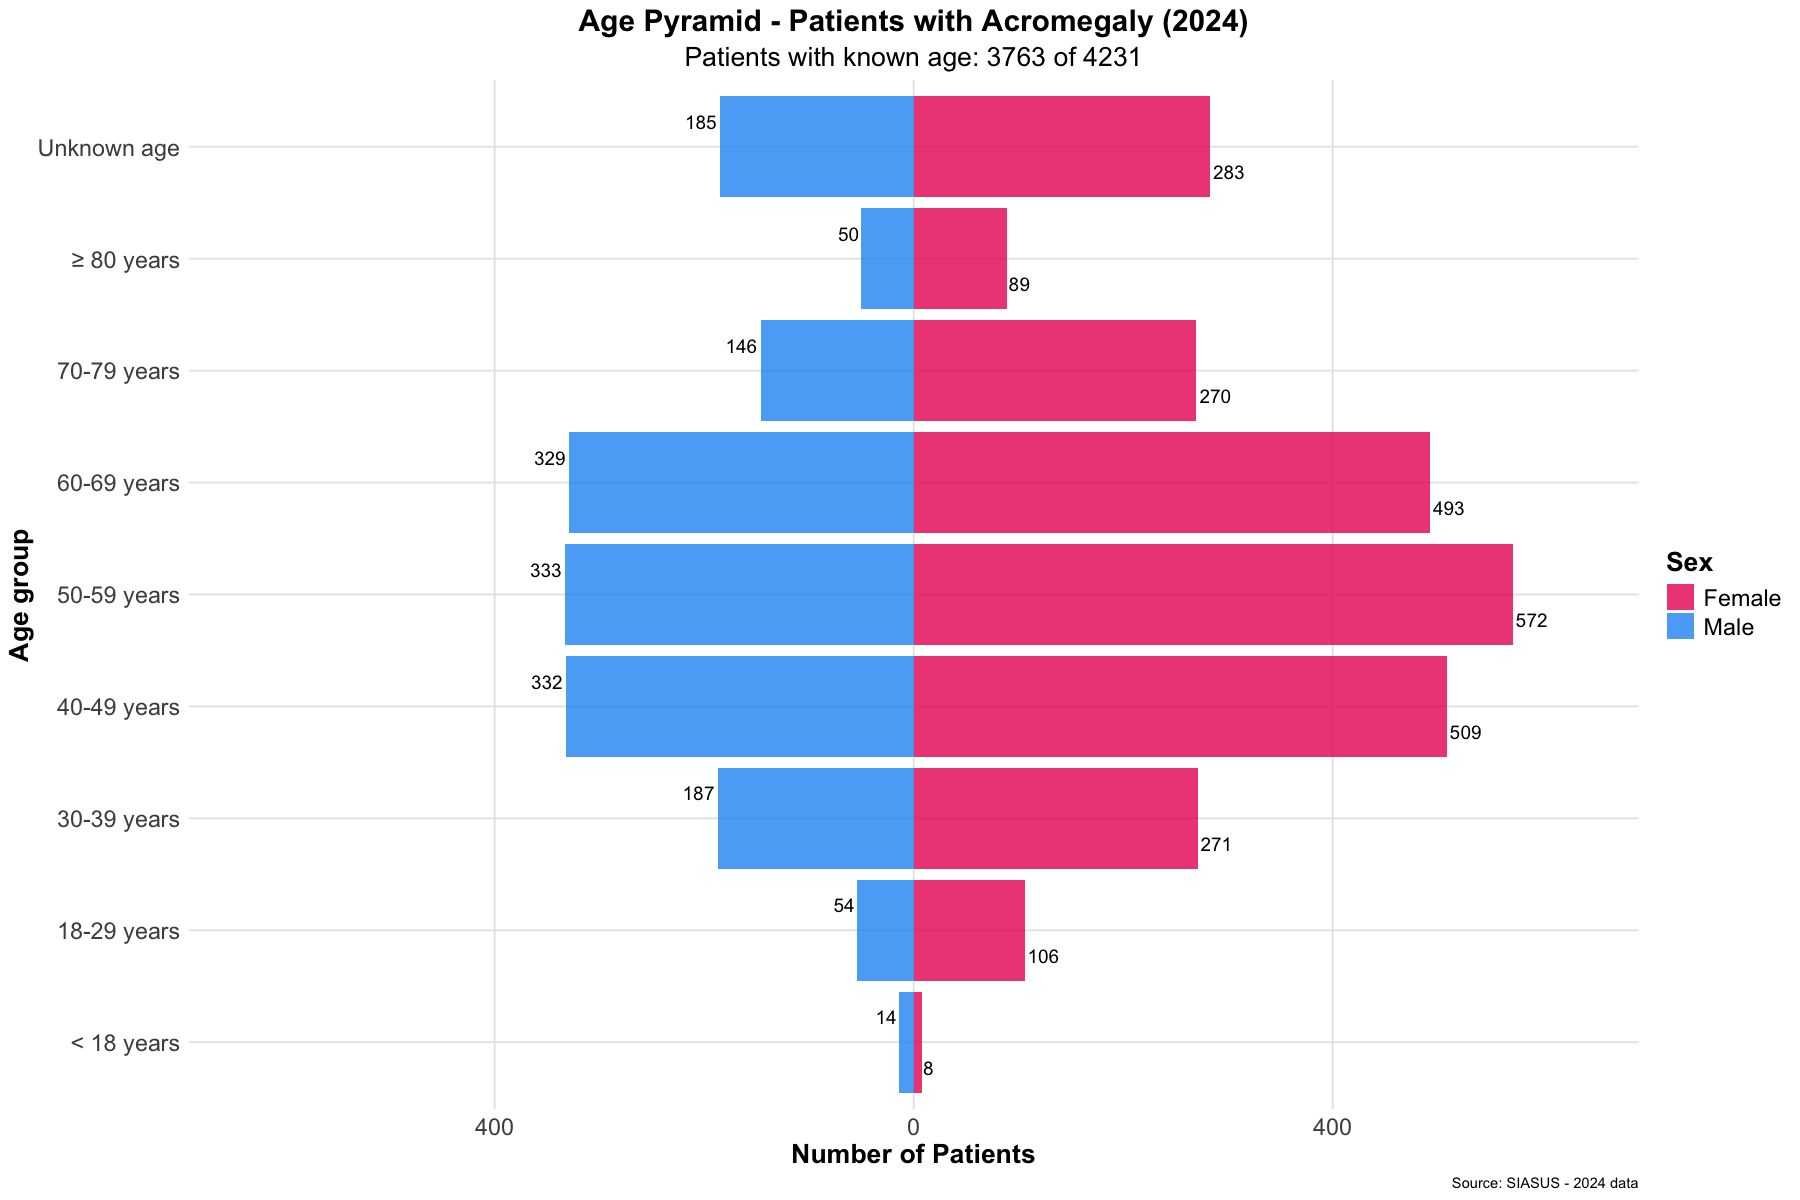

In [21]:
# Criar pirâmide etária
library(ggplot2)

# Filtrar apenas F e M para a pirâmide
dados_piramide_plot <- dados_piramide %>%
  filter(sexo_tratado %in% c("F", "M"))

# Calcular máximo para ajustar escala
max_valor <- max(abs(dados_piramide_plot$qtd_plot))

# Criar pirâmide etária
piramide_etaria <- ggplot(dados_piramide_plot, aes(x = faixa_etaria, y = qtd_plot, fill = sexo_tratado)) +
  geom_bar(stat = "identity", position = "identity", alpha = 0.8) +
  coord_flip() +
  scale_x_discrete(labels = traduzir_texto) +
  scale_y_continuous(
    labels = function(x) abs(x),
    limits = c(-max_valor * 1.1, max_valor * 1.1)
  ) +
  scale_fill_manual(
    values = c("F" = "#E91E63", "M" = "#2196F3"),
    labels = c("F" = "Female", "M" = "Male")
  ) +
  labs(
    title = "Age Pyramid - Patients with Acromegaly (2024)",
    subtitle = paste0("Patients with known age: ", sum(!is.na(dados_pacientes_unicos$PA_IDADE)), " of ", n_pacientes),
    x = "Age group",
    y = "Number of Patients",
    fill = "Sex",
    caption = "Source: SIASUS - 2024 data"
  ) +
  theme_minimal() +
  theme(
    plot.title = element_text(size = 18, face = "bold", hjust = 0.5),
    plot.subtitle = element_text(size = 16, hjust = 0.5),
    axis.text.x = element_text(size = 14),
    axis.text.y = element_text(size = 14),
    axis.title = element_text(size = 16, face = "bold"),
    legend.title = element_text(size = 16, face = "bold"),
    legend.text = element_text(size = 14),
    panel.grid.major = element_line(color = "grey90"),
    panel.grid.minor = element_blank()
  ) +
  geom_text(
    aes(label = ifelse(qtd_plot != 0, abs(qtd_plot), "")),
    position = position_dodge(width = 0.9),
    hjust = ifelse(dados_piramide_plot$qtd_plot >= 0, -0.1, 1.1),
    size = 4,
    color = "black"
  )

# Configurar tamanho da exibição no notebook
options(repr.plot.width = 15, repr.plot.height = 10)

# Exibir gráfico com tamanho maior
print(piramide_etaria)

# Salvar gráfico
ggsave(gerar_nome_png("piramide_etaria"), 
       plot = piramide_etaria, 
       width = 15, height = 10, dpi = 300)

cat("\n✅ Pirâmide etária salva em:", gerar_nome_png("piramide_etaria"), "\n")

In [22]:
# Resumo estatístico da pirâmide etária
cat("=== RESUMO DA PIRÂMIDE ETÁRIA ===\n\n")

# Estatísticas por sexo
resumo_sexo <- dados_piramide %>%
  filter(sexo_tratado %in% c("F", "M")) %>%
  group_by(sexo_tratado) %>%
  summarise(
    total_pacientes = sum(quantidade_pacientes),
    .groups = "drop"
  ) %>%
  mutate(
    percentual = round(total_pacientes / sum(total_pacientes) * 100, 1)
  )

# Adicionar linha de total
total_resumo_sexo <- resumo_sexo %>%
  summarise(
    sexo_tratado = "TOTAL",
    total_pacientes = sum(total_pacientes),
    percentual = 100.0
  )

# Combinar dados com total
resumo_sexo_com_total <- bind_rows(resumo_sexo, total_resumo_sexo)

cat("Distribuição por sexo:\n")
print(resumo_sexo_com_total)

# Estatísticas por faixa etária
resumo_idade <- dados_piramide %>%
  filter(sexo_tratado %in% c("F", "M")) %>%
  group_by(faixa_etaria) %>%
  summarise(
    total_pacientes = sum(quantidade_pacientes),
    .groups = "drop"
  ) %>%
  mutate(
    percentual = round(total_pacientes / sum(total_pacientes) * 100, 1)
  ) %>%
  arrange(faixa_etaria)

# Adicionar linha de total
total_resumo_idade <- resumo_idade %>%
  summarise(
    faixa_etaria = "TOTAL",
    total_pacientes = sum(total_pacientes),
    percentual = 100.0
  )

# Combinar dados com total
resumo_idade_com_total <- bind_rows(resumo_idade, total_resumo_idade)

cat("\nDistribuição por faixa etária:\n")
print(resumo_idade_com_total)

# Idade mediana por sexo
idade_mediana <- dados_pacientes_unicos %>%
  filter(AP_SEXO %in% c("F", "M")) %>%
  group_by(AP_SEXO) %>%
  summarise(
    idade_mediana = median(as.numeric(PA_IDADE), na.rm = TRUE),
    idade_media = round(mean(as.numeric(PA_IDADE), na.rm = TRUE), 1),
    .groups = "drop"
  )

cat("\nIdade mediana e média por sexo:\n")
print(idade_mediana)

=== RESUMO DA PIRÂMIDE ETÁRIA ===

Distribuição por sexo:
# A tibble: 3 × 3
  sexo_tratado total_pacientes percentual
  <chr>                  <int>      <dbl>
1 F                       2601       61.5
2 M                       1630       38.5
3 TOTAL                   4231      100  

Distribuição por faixa etária:
# A tibble: 10 × 3
   faixa_etaria       total_pacientes percentual
   <chr>                        <int>      <dbl>
 1 < 18 anos                       22        0.5
 2 18-29 anos                     160        3.8
 3 30-39 anos                     458       10.8
 4 40-49 anos                     841       19.9
 5 50-59 anos                     905       21.4
 6 60-69 anos                     822       19.4
 7 70-79 anos                     416        9.8
 8 ≥ 80 anos                      139        3.3
 9 Idade desconhecida             468       11.1
10 TOTAL                         4231      100  

Idade mediana e média por sexo:
# A tibble: 2 × 3
  AP_SEXO idade_mediana 

### 6.4 Análise por Raça/Cor


In [23]:
# Análise por raça/cor
# Primeiro, vamos verificar quais valores existem na coluna PA_RACACOR
cat("Valores únicos em PA_RACACOR:\n")
print(unique(dados_pacientes_unicos$PA_RACACOR))

# Criar tabela de raça/cor com nomes padronizados
pacientes_por_raca_cor <- dados_pacientes_unicos %>%
  mutate(
    raca_cor = case_when(
      PA_RACACOR == "01" ~ "Branca",
      PA_RACACOR == "02" ~ "Preta",
      PA_RACACOR == "03" ~ "Parda",
      PA_RACACOR == "04" ~ "Amarela",
      PA_RACACOR == "05" ~ "Indígena",
      PA_RACACOR == "99" ~ "Não informado",
      is.na(PA_RACACOR) | PA_RACACOR == "" ~ "Não informado",
      TRUE ~ "Outros"
    )
  ) %>%
  group_by(raca_cor) %>%
  summarise(
    quantidade_pacientes = n_distinct(AP_CNSPCN),  # Contar AP_CNSPCN únicos
    .groups = "drop"
  ) %>%
  mutate(
    percentual = round(quantidade_pacientes / sum(quantidade_pacientes) * 100, 2)
  ) %>%
  arrange(desc(quantidade_pacientes))

# Adicionar linha de total
total_raca_cor <- pacientes_por_raca_cor %>%
  summarise(
    raca_cor = "TOTAL",
    quantidade_pacientes = sum(quantidade_pacientes),
    percentual = 100.0
  )

# Combinar dados com total
pacientes_por_raca_cor_com_total <- bind_rows(pacientes_por_raca_cor, total_raca_cor)

cat("Distribuição de pacientes únicos por raça/cor:\n")
print(pacientes_por_raca_cor_com_total)

# Validação
total_raca_cor_validacao <- sum(pacientes_por_raca_cor$quantidade_pacientes)
cat("\n✅ Validação - Total de pacientes únicos por raça/cor:", total_raca_cor_validacao, "\n")
cat("✅ Deve ser igual a:", n_distinct(dados_pacientes_unicos$AP_CNSPCN), "\n")

# Exportar para Excel
library(openxlsx)
exportar_xlsx(pacientes_por_raca_cor_com_total, gerar_nome_arquivo("raca_cor"))
cat("✅ Tabela exportada para:", gerar_nome_arquivo("raca_cor"), "\n")

Valores únicos em PA_RACACOR:
[1] NA   "01" "03" "04" "02"
Distribuição de pacientes únicos por raça/cor:
# A tibble: 6 × 3
  raca_cor      quantidade_pacientes percentual
  <chr>                        <int>      <dbl>
1 Branca                        2142       50.6
2 Parda                         1363       32.2
3 Não informado                  468       11.1
4 Preta                          182        4.3
5 Amarela                         76        1.8
6 TOTAL                         4231      100  

✅ Validação - Total de pacientes únicos por raça/cor: 4231 
✅ Deve ser igual a: 4231 
✅ Tabela exportada para: ../resultados/third_review/20261013_data2024_race_colour.xlsx 


### 6.5 Distribuição por UF do **estabelecimento de dispensação** (contagens, sem taxas)

**Terceira revisão, item 3.** `AP_UFMUN` é o município/UF do **estabelecimento**. Estas tabelas descrevem **locais de dispensação** e não devem ser divididas pela população residente. As taxas por milhão são calculadas pela **residência** do paciente (`AP_MUNPCN`) na seção 6.7.


In [24]:
# Análise por UF do estabelecimento (AP_UFMUN = município do estabelecimento)
codigo_uf_para_sigla <- data.frame(
  codigo_uf = c("11", "12", "13", "14", "15", "16", "17", "21", "22", "23",
                "24", "25", "26", "27", "28", "29", "31", "32", "33", "35",
                "41", "42", "43", "50", "51", "52", "53"),
  uf_sigla = c("RO", "AC", "AM", "RR", "PA", "AP", "TO", "MA", "PI", "CE",
               "RN", "PB", "PE", "AL", "SE", "BA", "MG", "ES", "RJ", "SP",
               "PR", "SC", "RS", "MS", "MT", "GO", "DF")
)

pacientes_por_uf_estabelecimento <- dados_pacientes_unicos %>%
  mutate(codigo_uf = substr(AP_UFMUN, 1, 2)) %>%
  left_join(codigo_uf_para_sigla, by = "codigo_uf") %>%
  mutate(uf_sigla = ifelse(is.na(uf_sigla), "Não identificado", uf_sigla)) %>%
  count(uf_sigla, name = "pacientes_dispensados") %>%
  mutate(percentual = round(pacientes_dispensados / sum(pacientes_dispensados) * 100, 2)) %>%
  arrange(desc(pacientes_dispensados))

pacientes_por_uf_estabelecimento_com_total <- bind_rows(
  pacientes_por_uf_estabelecimento,
  tibble::tibble(uf_sigla = "TOTAL", pacientes_dispensados = sum(pacientes_por_uf_estabelecimento$pacientes_dispensados),
                 percentual = 100)
)

cat("Pacientes únicos por UF do estabelecimento de dispensação (contagens):\n")
print(pacientes_por_uf_estabelecimento_com_total, n = Inf)
stopifnot(sum(pacientes_por_uf_estabelecimento$pacientes_dispensados) == n_pacientes)

exportar_xlsx(pacientes_por_uf_estabelecimento_com_total, gerar_nome_arquivo("uf_estabelecimento_dispensacao"))
cat("✅ Tabela exportada para:", gerar_nome_arquivo("uf_estabelecimento_dispensacao"), "\n")


Pacientes únicos por UF do estabelecimento de dispensação (contagens):
# A tibble: 28 × 3
   uf_sigla pacientes_dispensados percentual
   <chr>                    <int>      <dbl>
 1 SP                        1567      37.0 
 2 MG                         462      10.9 
 3 RS                         302       7.14
 4 PR                         252       5.96
 5 RJ                         205       4.85
 6 CE                         188       4.44
 7 SC                         178       4.21
 8 BA                         135       3.19
 9 MA                         108       2.55
10 PE                         108       2.55
11 GO                         104       2.46
12 PB                          87       2.06
13 ES                          86       2.03
14 DF                          70       1.65
15 PA                          68       1.61
16 MS                          62       1.47
17 RN                          60       1.42
18 PI                          38       0.9 
19 MT     

### 6.6 Distribuição por região do **estabelecimento de dispensação** (contagens, sem taxas)


In [25]:
# Mapeamento de UF para Região
uf_para_regiao <- data.frame(
  uf_sigla = c("AC", "AL", "AP", "AM", "BA", "CE", "DF", "ES", "GO", "MA",
               "MT", "MS", "MG", "PA", "PB", "PR", "PE", "PI", "RJ", "RN",
               "RS", "RO", "RR", "SC", "SP", "SE", "TO"),
  regiao = c("Norte", "Nordeste", "Norte", "Norte", "Nordeste", "Nordeste",
             "Centro-Oeste", "Sudeste", "Centro-Oeste", "Nordeste",
             "Centro-Oeste", "Centro-Oeste", "Sudeste", "Norte", "Nordeste",
             "Sul", "Nordeste", "Nordeste", "Sudeste", "Nordeste",
             "Sul", "Norte", "Norte", "Sul", "Sudeste", "Nordeste", "Norte")
)

pacientes_por_regiao_estabelecimento <- pacientes_por_uf_estabelecimento %>%
  left_join(uf_para_regiao, by = "uf_sigla") %>%
  mutate(regiao = ifelse(is.na(regiao), "Não informado", regiao)) %>%
  group_by(regiao) %>%
  summarise(pacientes_dispensados = sum(pacientes_dispensados), .groups = "drop") %>%
  mutate(percentual = round(pacientes_dispensados / sum(pacientes_dispensados) * 100, 2)) %>%
  arrange(desc(pacientes_dispensados))

pacientes_por_regiao_estabelecimento_com_total <- bind_rows(
  pacientes_por_regiao_estabelecimento,
  tibble::tibble(regiao = "TOTAL", pacientes_dispensados = sum(pacientes_por_regiao_estabelecimento$pacientes_dispensados),
                 percentual = 100)
)

cat("Pacientes únicos por região do estabelecimento de dispensação (contagens):\n")
print(pacientes_por_regiao_estabelecimento_com_total)

exportar_xlsx(pacientes_por_regiao_estabelecimento_com_total, gerar_nome_arquivo("regiao_estabelecimento_dispensacao"))
cat("✅ Tabela exportada para:", gerar_nome_arquivo("regiao_estabelecimento_dispensacao"), "\n")


Pacientes únicos por região do estabelecimento de dispensação (contagens):
# A tibble: 6 × 3
  regiao       pacientes_dispensados percentual
  <chr>                        <int>      <dbl>
1 Sudeste                       2320      54.8 
2 Nordeste                       784      18.5 
3 Sul                            732      17.3 
4 Centro-Oeste                   269       6.36
5 Norte                          126       2.98
6 TOTAL                         4231     100   
✅ Tabela exportada para: ../resultados/third_review/20261013_data2024_region_dispensing_facility.xlsx 


### 6.7 Taxas por **residência** do paciente e comparação residência x dispensação (terceira revisão, item 3)

- Numerador: pacientes únicos pelo município de residência `AP_MUNPCN` (campo do **AM**, presente em todos os registros) no registro mais recente de 2024. Residência é considerada ausente quando o código não corresponde a uma UF válida.
- Denominador: população residente estimada para 2024 (IBGE), por UF e região.
- Taxa por milhão de habitantes com IC95% exato de Poisson.
- Observação: na versão anterior, a residência vinha de `PA_MUNPCN` (Produção Ambulatorial), que fica ausente sempre que o registro não tem correspondência no PA. A tabela abaixo mostra as duas fontes para os mesmos pacientes.


In [26]:
# Populações residentes por UF (estimativas IBGE 2024)
populacao_uf <- data.frame(
  uf_sigla = c("RO", "AC", "AM", "RR", "PA", "AP", "TO",
               "MA", "PI", "CE", "RN", "PB", "PE", "AL", "SE", "BA",
               "MG", "ES", "RJ", "SP",
               "PR", "SC", "RS",
               "MS", "MT", "GO", "DF"),
  populacao = c(1815278, 906876, 4269995, 652713, 8777124, 877613, 1607363,
                7153262, 3289290, 9240580, 3560903, 4059905, 9674793, 3365351, 2338474, 14985284,
                21411923, 4108508, 17463349, 46649132,
                11597484, 7338473, 11466630,
                2839188, 3567234, 7206589, 3094325)
)

ic_poisson <- function(x, pop, por = 1e6) {
  tibble::tibble(
    taxa_por_milhao = round(x / pop * por, 2),
    ic95_inferior = round(ifelse(x == 0, 0, qchisq(0.025, 2 * x) / 2) / pop * por, 2),
    ic95_superior = round(qchisq(0.975, 2 * (x + 1)) / 2 / pop * por, 2)
  )
}

pacientes_geo <- dados_pacientes_unicos %>%
  # AP_MUNPCN foi padronizado com 7 dígitos na seção 2; o código IBGE de 6 dígitos são os últimos 6
  mutate(cod_uf_res = substr(str_sub(AP_MUNPCN, -6), 1, 2), cod_uf_fac = substr(AP_UFMUN, 1, 2),
         cod_uf_res_pa = substr(PA_MUNPCN, 1, 2)) %>%
  left_join(codigo_uf_para_sigla %>% rename(uf_residencia = uf_sigla), by = c("cod_uf_res" = "codigo_uf")) %>%
  left_join(codigo_uf_para_sigla %>% rename(uf_dispensacao = uf_sigla), by = c("cod_uf_fac" = "codigo_uf")) %>%
  left_join(codigo_uf_para_sigla %>% rename(uf_residencia_pa = uf_sigla), by = c("cod_uf_res_pa" = "codigo_uf")) %>%
  left_join(uf_para_regiao %>% rename(regiao_residencia = regiao), by = c("uf_residencia" = "uf_sigla")) %>%
  left_join(uf_para_regiao %>% rename(regiao_dispensacao = regiao), by = c("uf_dispensacao" = "uf_sigla")) %>%
  left_join(uf_para_regiao %>% rename(regiao_residencia_pa = regiao), by = c("uf_residencia_pa" = "uf_sigla")) %>%
  mutate(residencia_ausente = is.na(uf_residencia))

cat("Pacientes com residência ausente (AP_MUNPCN, AM):", sum(pacientes_geo$residencia_ausente), "\n")
cat("Pacientes com residência ausente se fosse usado PA_MUNPCN (PA):", sum(is.na(pacientes_geo$uf_residencia_pa)), "\n")

# Taxas por UF de residência
pacientes_por_uf_residencia <- pacientes_geo %>%
  filter(!residencia_ausente) %>%
  count(uf_sigla = uf_residencia, name = "pacientes_residentes") %>%
  right_join(populacao_uf, by = "uf_sigla") %>%
  mutate(pacientes_residentes = coalesce(pacientes_residentes, 0L)) %>%
  left_join(uf_para_regiao, by = "uf_sigla") %>%
  bind_cols(ic_poisson(.$pacientes_residentes, .$populacao)) %>%
  arrange(desc(taxa_por_milhao))

# Taxas por região de residência
pacientes_por_regiao_residencia <- pacientes_por_uf_residencia %>%
  group_by(regiao) %>%
  summarise(pacientes_residentes = sum(pacientes_residentes), populacao = sum(populacao), .groups = "drop") %>%
  bind_cols(ic_poisson(.$pacientes_residentes, .$populacao)) %>%
  arrange(desc(taxa_por_milhao))
total_residencia <- tibble::tibble(regiao = "Brasil (residência conhecida)",
                                   pacientes_residentes = sum(pacientes_por_regiao_residencia$pacientes_residentes),
                                   populacao = sum(populacao_uf$populacao)) %>%
  bind_cols(ic_poisson(.$pacientes_residentes, .$populacao))
pacientes_por_regiao_residencia <- bind_rows(
  pacientes_por_regiao_residencia, total_residencia,
  tibble::tibble(regiao = "Residência ausente", pacientes_residentes = sum(pacientes_geo$residencia_ausente))
)

cat("\nTaxas por região de residência (por milhão, IC95% Poisson exato):\n")
print(pacientes_por_regiao_residencia)
cat("\nTaxas por UF de residência:\n")
print(pacientes_por_uf_residencia, n = Inf)

# Residência ausente por região de dispensação (item 3d)
residencia_ausente_por_regiao_dispensacao <- pacientes_geo %>%
  group_by(regiao_dispensacao) %>%
  summarise(pacientes = n(), residencia_ausente_AM = sum(residencia_ausente),
            residencia_ausente_se_PA = sum(is.na(uf_residencia_pa)), .groups = "drop") %>%
  mutate(pct_ausente_se_PA = round(residencia_ausente_se_PA / pacientes * 100, 1))
print(residencia_ausente_por_regiao_dispensacao)

# Comparação pareada residência x dispensação entre pacientes com residência conhecida (item 3d)
pareado <- pacientes_geo %>% filter(!residencia_ausente)
matriz_regiao_residencia_dispensacao <- pareado %>%
  count(regiao_residencia, regiao_dispensacao) %>%
  pivot_wider(names_from = regiao_dispensacao, values_from = n, values_fill = 0)
print(matriz_regiao_residencia_dispensacao)

resumo_pareado <- tibble::tibble(
  indicador = c("Pacientes com residência conhecida (conjunto pareado)",
                "Dispensados na mesma UF de residência",
                "Dispensados em outra UF",
                "Dispensados na mesma região de residência",
                "Dispensados em outra região"),
  pacientes = c(nrow(pareado), sum(pareado$uf_residencia == pareado$uf_dispensacao),
                sum(pareado$uf_residencia != pareado$uf_dispensacao),
                sum(pareado$regiao_residencia == pareado$regiao_dispensacao),
                sum(pareado$regiao_residencia != pareado$regiao_dispensacao))
) %>% mutate(percentual = round(pacientes / nrow(pareado) * 100, 2))
print(resumo_pareado)

# Mesmo conjunto de pacientes nos dois lados (para comparações socioeconômicas)
regiao_mesmo_conjunto <- full_join(
  pareado %>% count(regiao = regiao_residencia, name = "pacientes_por_residencia"),
  pareado %>% count(regiao = regiao_dispensacao, name = "pacientes_por_dispensacao"),
  by = "regiao"
) %>% mutate(diferenca_dispensacao_menos_residencia = pacientes_por_dispensacao - pacientes_por_residencia)
uf_mesmo_conjunto <- full_join(
  pareado %>% count(uf_sigla = uf_residencia, name = "pacientes_por_residencia"),
  pareado %>% count(uf_sigla = uf_dispensacao, name = "pacientes_por_dispensacao"),
  by = "uf_sigla"
) %>% mutate(across(where(is.numeric), ~ coalesce(.x, 0L)),
             diferenca_dispensacao_menos_residencia = pacientes_por_dispensacao - pacientes_por_residencia)
print(regiao_mesmo_conjunto)

# Fonte anterior (PA_MUNPCN) x fonte corrigida (AP_MUNPCN), por região, para os mesmos pacientes
regiao_fontes_residencia <- full_join(
  pacientes_geo %>% count(regiao = coalesce(regiao_residencia, "Ausente"), name = "residencia_AP_MUNPCN"),
  pacientes_geo %>% count(regiao = coalesce(regiao_residencia_pa, "Ausente"), name = "residencia_PA_MUNPCN_anterior"),
  by = "regiao"
) %>% left_join(pacientes_geo %>% count(regiao = regiao_dispensacao, name = "dispensacao_AP_UFMUN"), by = "regiao")
print(regiao_fontes_residencia)

exportar_xlsx(list("regiao_residencia_taxas" = pacientes_por_regiao_residencia,
                          "uf_residencia_taxas" = pacientes_por_uf_residencia,
                          "ausente_por_regiao_dispensacao" = residencia_ausente_por_regiao_dispensacao,
                          "matriz_residencia_x_dispensacao" = matriz_regiao_residencia_dispensacao,
                          "resumo_pareado" = resumo_pareado,
                          "regiao_mesmo_conjunto" = regiao_mesmo_conjunto,
                          "uf_mesmo_conjunto" = uf_mesmo_conjunto,
                          "fontes_residencia" = regiao_fontes_residencia),
                     gerar_nome_arquivo("geografia_residencia_taxas"))
cat("✅ Tabelas geográficas exportadas para:", gerar_nome_arquivo("geografia_residencia_taxas"), "\n")


Pacientes com residência ausente (AP_MUNPCN, AM): 0 
Pacientes com residência ausente se fosse usado PA_MUNPCN (PA): 468 

Taxas por região de residência (por milhão, IC95% Poisson exato):
# A tibble: 7 × 6
  regiao            pacientes_residentes populacao taxa_por_milhao ic95_inferior
  <chr>                            <int>     <dbl>           <dbl>         <dbl>
1 Sudeste                           2309  89632912           25.8          24.7 
2 Sul                                738  30402587           24.3          22.6 
3 Centro-Oeste                       268  16707336           16.0          14.2 
4 Nordeste                           788  57667842           13.7          12.7 
5 Norte                              128  18906962            6.77          5.65
6 Brasil (residênc…                 4231 213317639           19.8          19.2 
7 Residência ausen…                    0        NA           NA            NA   
# ℹ 1 more variable: ic95_superior <dbl>

Taxas por UF de residê

In [27]:
# Resumo geral das análises demográficas
cat("=== RESUMO GERAL DAS ANÁLISES DEMOGRÁFICAS ===\n\n")
cat("📊 TOTAL DE PACIENTES ÚNICOS EM 2024 (CNS válido):", n_pacientes, "\n\n")
cat("📋 Tabelas geradas em:", pasta_resultados, "\n")
cat("✅ Todas as contagens são baseadas em AP_CNSPCN únicos e não ausentes\n")


=== RESUMO GERAL DAS ANÁLISES DEMOGRÁFICAS ===

📊 TOTAL DE PACIENTES ÚNICOS EM 2024 (CNS válido): 4231 

📋 Tabelas geradas em: ../resultados/third_review/ 
✅ Todas as contagens são baseadas em AP_CNSPCN únicos e não ausentes


## 7. Análise de Medicamentos


### 7.1 Dicionário de Medicamentos SIGTAP


In [28]:
# Dicionário de medicamentos SIGTAP (AP_PRIPAL) - Acromegalia
# Lista completa dos códigos de procedimento incluídos (item 8a)
codigo_nomes <- c(
    "0604290039" = "OCTREOTIDA LAR 30 MG INJETÁVEL",
    "0604290080" = "LANREOTIDA 120 MG INJETÁVEL",
    "0604030037" = "CABERGOLINA 0,5 MG",
    "0604290020" = "OCTREOTIDA LAR 20 MG INJETÁVEL",
    "0604290071" = "LANREOTIDA 90 MG INJETÁVEL",
    "0604290063" = "LANREOTIDA 60 MG INJETÁVEL",
    "0604290012" = "OCTREOTIDA LAR 10 MG INJETÁVEL",
    "0604290047" = "OCTREOTIDA 0,1 MG/ML INJETÁVEL"
)

tabela_sigtap <- tibble::tibble(codigo_sigtap = names(codigo_nomes), descricao = unname(codigo_nomes)) %>%
  mutate(
    codigo_formatado = paste0(substr(codigo_sigtap, 1, 2), ".", substr(codigo_sigtap, 3, 4), ".",
                              substr(codigo_sigtap, 5, 6), ".", substr(codigo_sigtap, 7, 9), "-",
                              substr(codigo_sigtap, 10, 10)),
    principio_ativo = principio_ativo(codigo_sigtap)
  ) %>%
  left_join(dados_unificados %>% count(codigo_sigtap = AP_PRIPAL, name = "registros_2024"), by = "codigo_sigtap") %>%
  left_join(dados_unificados %>% group_by(codigo_sigtap = AP_PRIPAL) %>%
              summarise(pacientes_2024 = n_distinct(AP_CNSPCN), .groups = "drop"), by = "codigo_sigtap") %>%
  select(codigo_sigtap, codigo_formatado, principio_ativo, descricao, registros_2024, pacientes_2024) %>%
  arrange(principio_ativo, codigo_sigtap)

stopifnot(all(dados_unificados$AP_PRIPAL %in% names(codigo_nomes)))
print(tabela_sigtap)
exportar_xlsx(tabela_sigtap, gerar_nome_arquivo("codigos_sigtap"))


# A tibble: 8 × 6
  codigo_sigtap codigo_formatado principio_ativo descricao        registros_2024
  <chr>         <chr>            <chr>           <chr>                     <int>
1 0604030037    06.04.03.003-7   Cabergoline     CABERGOLINA 0,5…          15626
2 0604290063    06.04.29.006-3   Lanreotide      LANREOTIDA 60 M…            339
3 0604290071    06.04.29.007-1   Lanreotide      LANREOTIDA 90 M…           2359
4 0604290080    06.04.29.008-0   Lanreotide      LANREOTIDA 120 …           5938
5 0604290012    06.04.29.001-2   Octreotide      OCTREOTIDA LAR …            653
6 0604290020    06.04.29.002-0   Octreotide      OCTREOTIDA LAR …           6497
7 0604290039    06.04.29.003-9   Octreotide      OCTREOTIDA LAR …           7130
8 0604290047    06.04.29.004-7   Octreotide      OCTREOTIDA 0,1 …             17
# ℹ 1 more variable: pacientes_2024 <int>


### 7.2 Combinações de Medicamentos por Paciente


In [29]:
# Verificar códigos únicos em AP_PRIPAL
cat("Códigos únicos encontrados em AP_PRIPAL:\n")
codigos_unicos <- dados_unificados %>%
  filter(!is.na(AP_PRIPAL)) %>%
  count(AP_PRIPAL, sort = TRUE)
print(codigos_unicos)

# Verificar se os códigos do dicionário estão presentes nos dados
cat("\nCódigos do dicionário presentes nos dados:\n")
codigos_dicionario <- names(codigo_nomes)
codigos_presentes <- codigos_unicos %>%
  filter(AP_PRIPAL %in% codigos_dicionario)
print(codigos_presentes)

# Testar o mapeamento diretamente
cat("\nTeste de mapeamento:\n")
teste_mapeamento <- dados_unificados %>%
  filter(!is.na(AP_PRIPAL)) %>%
  select(AP_PRIPAL) %>%
  distinct() %>%
  head(5) %>%
  mutate(
    AP_PRIPAL_NOME = recode(as.character(AP_PRIPAL), !!!codigo_nomes)
  )
print(teste_mapeamento)

# Verificar se os códigos nos dados têm prefixo "06"
cat("\nVerificando se códigos têm prefixo '06':\n")
codigos_com_prefixo <- dados_unificados %>%
  filter(!is.na(AP_PRIPAL)) %>%
  mutate(
    codigo_sem_prefixo = ifelse(str_starts(AP_PRIPAL, "06"), substr(AP_PRIPAL, 3, nchar(AP_PRIPAL)), AP_PRIPAL)
  ) %>%
  select(AP_PRIPAL, codigo_sem_prefixo) %>%
  distinct() %>%
  head(10)
print(codigos_com_prefixo)

# Criar tabela de combinações de medicamentos por paciente
# APLICAR O DICIONÁRIO PRIMEIRO, DEPOIS AGRUPAR PELOS NOMES
combinacoes_medicamentos <- dados_unificados %>%
  filter(!is.na(AP_CNSPCN) & !is.na(AP_PRIPAL)) %>%
  mutate(AP_PRIPAL_NOME = recode(as.character(AP_PRIPAL), !!!codigo_nomes)) %>%
  filter(!is.na(AP_PRIPAL_NOME)) %>%
  group_by(AP_CNSPCN) %>%
  summarise(
    medicamentos = paste(sort(unique(AP_PRIPAL_NOME)), collapse = " + "),
    quantidade_medicamentos = n_distinct(AP_PRIPAL_NOME),
    .groups = "drop"
  ) %>%
  group_by(medicamentos) %>%
  summarise(
    quantidade_pacientes = n_distinct(AP_CNSPCN),
    .groups = "drop"
  ) %>%
  arrange(desc(quantidade_pacientes))

# Adicionar linha de total
total_combinacoes <- combinacoes_medicamentos %>%
  summarise(
    medicamentos = "TOTAL",
    quantidade_pacientes = sum(quantidade_pacientes)
  )

# Combinar dados com total
combinacoes_medicamentos_com_total <- bind_rows(combinacoes_medicamentos, total_combinacoes)

cat("Combinações de medicamentos por paciente:\n")
print(combinacoes_medicamentos_com_total)

# Validação
total_combinacoes_validacao <- sum(combinacoes_medicamentos$quantidade_pacientes)
cat("\n✅ Validação - Total de pacientes com combinações:", total_combinacoes_validacao, "\n")

# Exportar para Excel
exportar_xlsx(combinacoes_medicamentos_com_total, gerar_nome_arquivo("combinacoes_medicamentos"))
cat("✅ Tabela exportada para:", gerar_nome_arquivo("combinacoes_medicamentos"), "\n")

Códigos únicos encontrados em AP_PRIPAL:
# A tibble: 8 × 2
  AP_PRIPAL      n
  <chr>      <int>
1 0604030037 15626
2 0604290039  7130
3 0604290020  6497
4 0604290080  5938
5 0604290071  2359
6 0604290012   653
7 0604290063   339
8 0604290047    17

Códigos do dicionário presentes nos dados:
# A tibble: 8 × 2
  AP_PRIPAL      n
  <chr>      <int>
1 0604030037 15626
2 0604290039  7130
3 0604290020  6497
4 0604290080  5938
5 0604290071  2359
6 0604290012   653
7 0604290063   339
8 0604290047    17

Teste de mapeamento:
# A tibble: 5 × 2
  AP_PRIPAL  AP_PRIPAL_NOME                
  <chr>      <chr>                         
1 0604290039 OCTREOTIDA LAR 30 MG INJETÁVEL
2 0604030037 CABERGOLINA 0,5 MG            
3 0604290020 OCTREOTIDA LAR 20 MG INJETÁVEL
4 0604290080 LANREOTIDA 120 MG INJETÁVEL   
5 0604290071 LANREOTIDA 90 MG INJETÁVEL    

Verificando se códigos têm prefixo '06':
# A tibble: 8 × 2
  AP_PRIPAL  codigo_sem_prefixo
  <chr>      <chr>             
1 0604290039 04290039      

### 7.2.1 Categorias mutuamente exclusivas por princípio ativo (Tabela 4, terceira revisão, item 7c)


In [30]:
# Conjunto de princípios ativos registrados para cada paciente em 2024
principios_paciente <- dados_unificados %>%
  mutate(principio = principio_ativo(AP_PRIPAL)) %>%
  group_by(AP_CNSPCN) %>%
  summarise(
    octreotida = any(principio == "Octreotide"),
    lanreotida = any(principio == "Lanreotide"),
    cabergolina = any(principio == "Cabergoline"),
    .groups = "drop"
  ) %>%
  mutate(
    categoria_analogo = case_when(
      octreotida & lanreotida ~ "Both analogues (octreotide and lanreotide)",
      octreotida ~ "Octreotide without lanreotide",
      lanreotida ~ "Lanreotide without octreotide",
      TRUE ~ "No somatostatin analogue (cabergoline only)"
    ),
    categoria_completa = case_when(
      octreotida & lanreotida & cabergolina ~ "Octreotide + lanreotide + cabergoline",
      octreotida & lanreotida ~ "Octreotide + lanreotide",
      octreotida & cabergolina ~ "Octreotide + cabergoline",
      lanreotida & cabergolina ~ "Lanreotide + cabergoline",
      octreotida ~ "Octreotide only",
      lanreotida ~ "Lanreotide only",
      cabergolina ~ "Cabergoline only"
    )
  )

tabela4_analogos <- principios_paciente %>%
  count(categoria_analogo, com_cabergolina = ifelse(cabergolina, "with cabergoline", "without cabergoline"),
        name = "pacientes") %>%
  pivot_wider(names_from = com_cabergolina, values_from = pacientes, values_fill = 0) %>%
  mutate(total = rowSums(across(where(is.numeric))),
         percentual = round(total / n_distinct(dados_unificados$AP_CNSPCN) * 100, 1)) %>%
  arrange(desc(total))
tabela4_analogos <- bind_rows(tabela4_analogos, tibble::tibble(
  categoria_analogo = "TOTAL", total = sum(tabela4_analogos$total), percentual = 100))

tabela4_completa <- principios_paciente %>%
  count(categoria_completa, name = "pacientes") %>%
  mutate(percentual = round(pacientes / sum(pacientes) * 100, 1)) %>%
  arrange(desc(pacientes))
tabela4_completa <- bind_rows(tabela4_completa, tibble::tibble(
  categoria_completa = "TOTAL", pacientes = sum(tabela4_completa$pacientes), percentual = 100))

stopifnot(tail(tabela4_completa$pacientes, 1) == n_distinct(dados_unificados$AP_CNSPCN))
print(tabela4_analogos)
print(tabela4_completa)

exportar_xlsx(list("analogos_mutuamente_exclusivos" = tabela4_analogos,
                          "combinacoes_exclusivas" = tabela4_completa),
                     gerar_nome_arquivo("tabela4_categorias_medicamentos"))


# A tibble: 5 × 5
  categoria_analogo    `with cabergoline` `without cabergoline` total percentual
  <chr>                             <int>                 <int> <dbl>      <dbl>
1 Octreotide without …                270                  1344  1614       38.1
2 No somatostatin ana…               1497                     0  1497       35.4
3 Lanreotide without …                240                   820  1060       25.1
4 Both analogues (oct…                 14                    46    60        1.4
5 TOTAL                                NA                    NA  4231      100  
# A tibble: 8 × 3
  categoria_completa                    pacientes percentual
  <chr>                                     <int>      <dbl>
1 Cabergoline only                           1497       35.4
2 Octreotide only                            1344       31.8
3 Lanreotide only                             820       19.4
4 Octreotide + cabergoline                    270        6.4
5 Lanreotide + cabergoline     

### 7.3 Medicamentos Mais Recentes por Paciente


In [31]:
# Selecionar medicamentos mais recentes por paciente
# Se houver empate na data, combinar os medicamentos
# APLICAR O DICIONÁRIO PRIMEIRO, DEPOIS AGRUPAR PELOS NOMES
medicamentos_mais_recentes <- dados_unificados %>%
  filter(!is.na(AP_CNSPCN) & !is.na(AP_PRIPAL)) %>%
  mutate(AP_PRIPAL_NOME = recode(as.character(AP_PRIPAL), !!!codigo_nomes)) %>%
  filter(!is.na(AP_PRIPAL_NOME)) %>%
  group_by(AP_CNSPCN) %>%
  filter(AP_CMP == max(AP_CMP, na.rm = TRUE)) %>%
  summarise(
    medicamentos_recentes = paste(sort(unique(AP_PRIPAL_NOME)), collapse = " + "),
    quantidade_medicamentos = n_distinct(AP_PRIPAL_NOME),
    data_mais_recente = max(AP_CMP, na.rm = TRUE),
    .groups = "drop"
  ) %>%
  group_by(medicamentos_recentes) %>%
  summarise(
    quantidade_pacientes = n_distinct(AP_CNSPCN),
    .groups = "drop"
  ) %>%
  arrange(desc(quantidade_pacientes))

# Adicionar linha de total
total_medicamentos_recentes <- medicamentos_mais_recentes %>%
  summarise(
    medicamentos_recentes = "TOTAL",
    quantidade_pacientes = sum(quantidade_pacientes)
  )

# Combinar dados com total
medicamentos_mais_recentes_com_total <- bind_rows(medicamentos_mais_recentes, total_medicamentos_recentes)

cat("Medicamentos mais recentes por paciente:\n")
print(medicamentos_mais_recentes_com_total)

# Validação
total_medicamentos_recentes_validacao <- sum(medicamentos_mais_recentes$quantidade_pacientes)
cat("\n✅ Validação - Total de pacientes com medicamentos recentes:", total_medicamentos_recentes_validacao, "\n")

# Exportar para Excel
exportar_xlsx(medicamentos_mais_recentes_com_total, gerar_nome_arquivo("medicamentos_recentes"))
cat("✅ Tabela exportada para:", gerar_nome_arquivo("medicamentos_recentes"), "\n")

Medicamentos mais recentes por paciente:
# A tibble: 15 × 2
   medicamentos_recentes                                    quantidade_pacientes
   <chr>                                                                   <int>
 1 CABERGOLINA 0,5 MG                                                       1785
 2 OCTREOTIDA LAR 30 MG INJETÁVEL                                            729
 3 LANREOTIDA 120 MG INJETÁVEL                                               664
 4 OCTREOTIDA LAR 20 MG INJETÁVEL                                            663
 5 LANREOTIDA 90 MG INJETÁVEL                                                264
 6 OCTREOTIDA LAR 10 MG INJETÁVEL                                             70
 7 LANREOTIDA 60 MG INJETÁVEL                                                 39
 8 CABERGOLINA 0,5 MG + LANREOTIDA 120 MG INJETÁVEL                            6
 9 OCTREOTIDA 0,1 MG/ML INJETÁVEL                                              3
10 CABERGOLINA 0,5 MG + OCTREOTIDA LAR 20 MG INJE

### 7.4 Análise Detalhada dos Medicamentos


In [32]:
# Tabela com a quantidade de doses dispensadas, valor produzido, valor pago pelo SUS, valor médio pago por dose, valor aprovado e total de doses aprovadas
tabela_medicamentos <- dados_unificados %>%
  filter(!is.na(AP_PRIPAL)) %>%
  mutate(
    AP_PRIPAL_NOME = recode(as.character(AP_PRIPAL), !!!codigo_nomes),
    PA_QTDPRO = as.numeric(PA_QTDPRO),
    PA_VALPRO = as.numeric(PA_VALPRO),
    PA_QTDAPR = as.numeric(PA_QTDAPR),
    PA_VALAPR = as.numeric(PA_VALAPR)
  ) %>%
  filter(!is.na(AP_PRIPAL_NOME)) %>%
  group_by(AP_PRIPAL_NOME) %>%
  summarise(
    # Coluna 1: Nome do medicamento
    medicamento = first(AP_PRIPAL_NOME),
    
    # Coluna 2: Quantidade de doses dispensadas (PA_QTDPRO)
    doses_dispensadas = sum(PA_QTDPRO, na.rm = TRUE),
    
    # Coluna 3: Valor em reais produzido (PA_VALPRO)
    valor_produzido = sum(PA_VALPRO, na.rm = TRUE),
    
    # Coluna 4: Valor médio por dose (calculado)
    valor_medio_dose = round(valor_produzido / doses_dispensadas, 2),
    
    # Coluna 5: Quantidade de doses aprovadas (PA_QTDAPR)
    doses_aprovadas = sum(PA_QTDAPR, na.rm = TRUE),
    
    # Coluna 6: Valor em reais pago pelo SUS (PA_VALAPR)
    valor_pago_sus = sum(PA_VALAPR, na.rm = TRUE),
    
    # Coluna 7: Valor médio pago por dose (calculado)
    valor_medio_pago = round(valor_pago_sus / doses_aprovadas, 2),
    
    # Coluna 8: Valor aprovado (PA_VALAPR - mesmo que valor pago pelo SUS)
    valor_aprovado = sum(PA_VALAPR, na.rm = TRUE),
    
    .groups = "drop"
  ) %>%
  select(-AP_PRIPAL_NOME) %>%  # Remove coluna duplicada
  arrange(desc(valor_produzido))

# Adicionar linha de total
total_linha <- tabela_medicamentos %>%
  summarise(
    medicamento = "TOTAL",
    doses_dispensadas = sum(doses_dispensadas),
    valor_produzido = sum(valor_produzido),
    valor_medio_dose = round(sum(valor_produzido) / sum(doses_dispensadas), 2),
    doses_aprovadas = sum(doses_aprovadas),
    valor_pago_sus = sum(valor_pago_sus),
    valor_medio_pago = round(sum(valor_pago_sus) / sum(doses_aprovadas), 2),
    valor_aprovado = sum(valor_aprovado)
  )

# Combinar dados com total
tabela_final <- bind_rows(tabela_medicamentos, total_linha)

# Exibir tabela completa
cat("=== TABELA DE MEDICAMENTOS - 8 COLUNAS ===\n\n")
print(tabela_final)

# Resumo das métricas
cat("\n=== RESUMO DAS MÉTRICAS ===\n")
cat("📊 Total de medicamentos analisados:", nrow(tabela_medicamentos), "\n")
cat("📊 Total de doses dispensadas:", sum(tabela_medicamentos$doses_dispensadas), "\n")
cat("📊 Total de doses aprovadas:", sum(tabela_medicamentos$doses_aprovadas), "\n")
cat("💰 Valor total produzido: R$", format(sum(tabela_medicamentos$valor_produzido), big.mark = ".", decimal.mark = ","), "\n")
cat("💰 Valor total pago pelo SUS: R$", format(sum(tabela_medicamentos$valor_pago_sus), big.mark = ".", decimal.mark = ","), "\n")

# Exportar para Excel com nome padronizado
exportar_xlsx(tabela_final, gerar_nome_arquivo("medicamentos_gasto"))
cat("\n✅ Tabela exportada para:", gerar_nome_arquivo("medicamentos_gasto"), "\n")

=== TABELA DE MEDICAMENTOS - 8 COLUNAS ===

# A tibble: 9 × 8
  medicamento doses_dispensadas valor_produzido valor_medio_dose doses_aprovadas
  <chr>                   <dbl>           <dbl>            <dbl>           <dbl>
1 OCTREOTIDA…               613        1125124.          1835.               612
2 CABERGOLIN…            189100         233698.             1.24          188302
3 OCTREOTIDA…             19330           7228.             0.37           19311
4 OCTREOTIDA…                13            376.            28.9               13
5 LANREOTIDA…             24568              0              0              24549
6 LANREOTIDA…               526              0              0                525
7 LANREOTIDA…              3184              0              0               3180
8 OCTREOTIDA…             11700              0              0              11671
9 TOTAL                  249034        1366426.             5.49          248163
# ℹ 3 more variables: valor_pago_sus <dbl>, val

#### 7.4.1 - Criação do Diagrama de Sankey e tabela de fluxo de uso de medicamentos

=== DIAGRAMA DE SANKEY - FORÇANDO ORDENAÇÃO E FLUXO ===
Total registros: 38455 
Total de transições: 34224 
Fluxos únicos (pronto para plotar): 683 

Preparando dados para Sankey...
# A tibble: 10 × 5
   x       next_x  node        next_node   value
   <fct>   <fct>   <chr>       <chr>       <int>
 1 2024-01 2024-01 Cabergolina Lan120          1
 2 2024-01 2024-01 Cabergolina Oct30           3
 3 2024-01 2024-01 Lan120      Cabergolina     1
 4 2024-01 2024-01 Lan90       Cabergolina     1
 5 2024-01 2024-01 OCTREOTIDA  Oct20           1
 6 2024-01 2024-01 Oct20       OCTREOTIDA      1
 7 2024-01 2024-01 Oct30       Oct20           2
 8 2024-01 2024-02 Cabergolina Cabergolina  1091
 9 2024-01 2024-02 Cabergolina Lan120         23
10 2024-01 2024-02 Cabergolina Lan90           1

Plotando Sankey com 12 colunas (meses)...


Warning message:
“The `size` argument of `element_rect()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the ggsankey package.
  Please report the issue at <https://github.com/davidsjoberg/ggsankey/issues>.”



✅ DIAGRAMA DE SANKEY CRIADO COM AS LINHAS DE FLUXO (Ordenação forçada aplicada)!


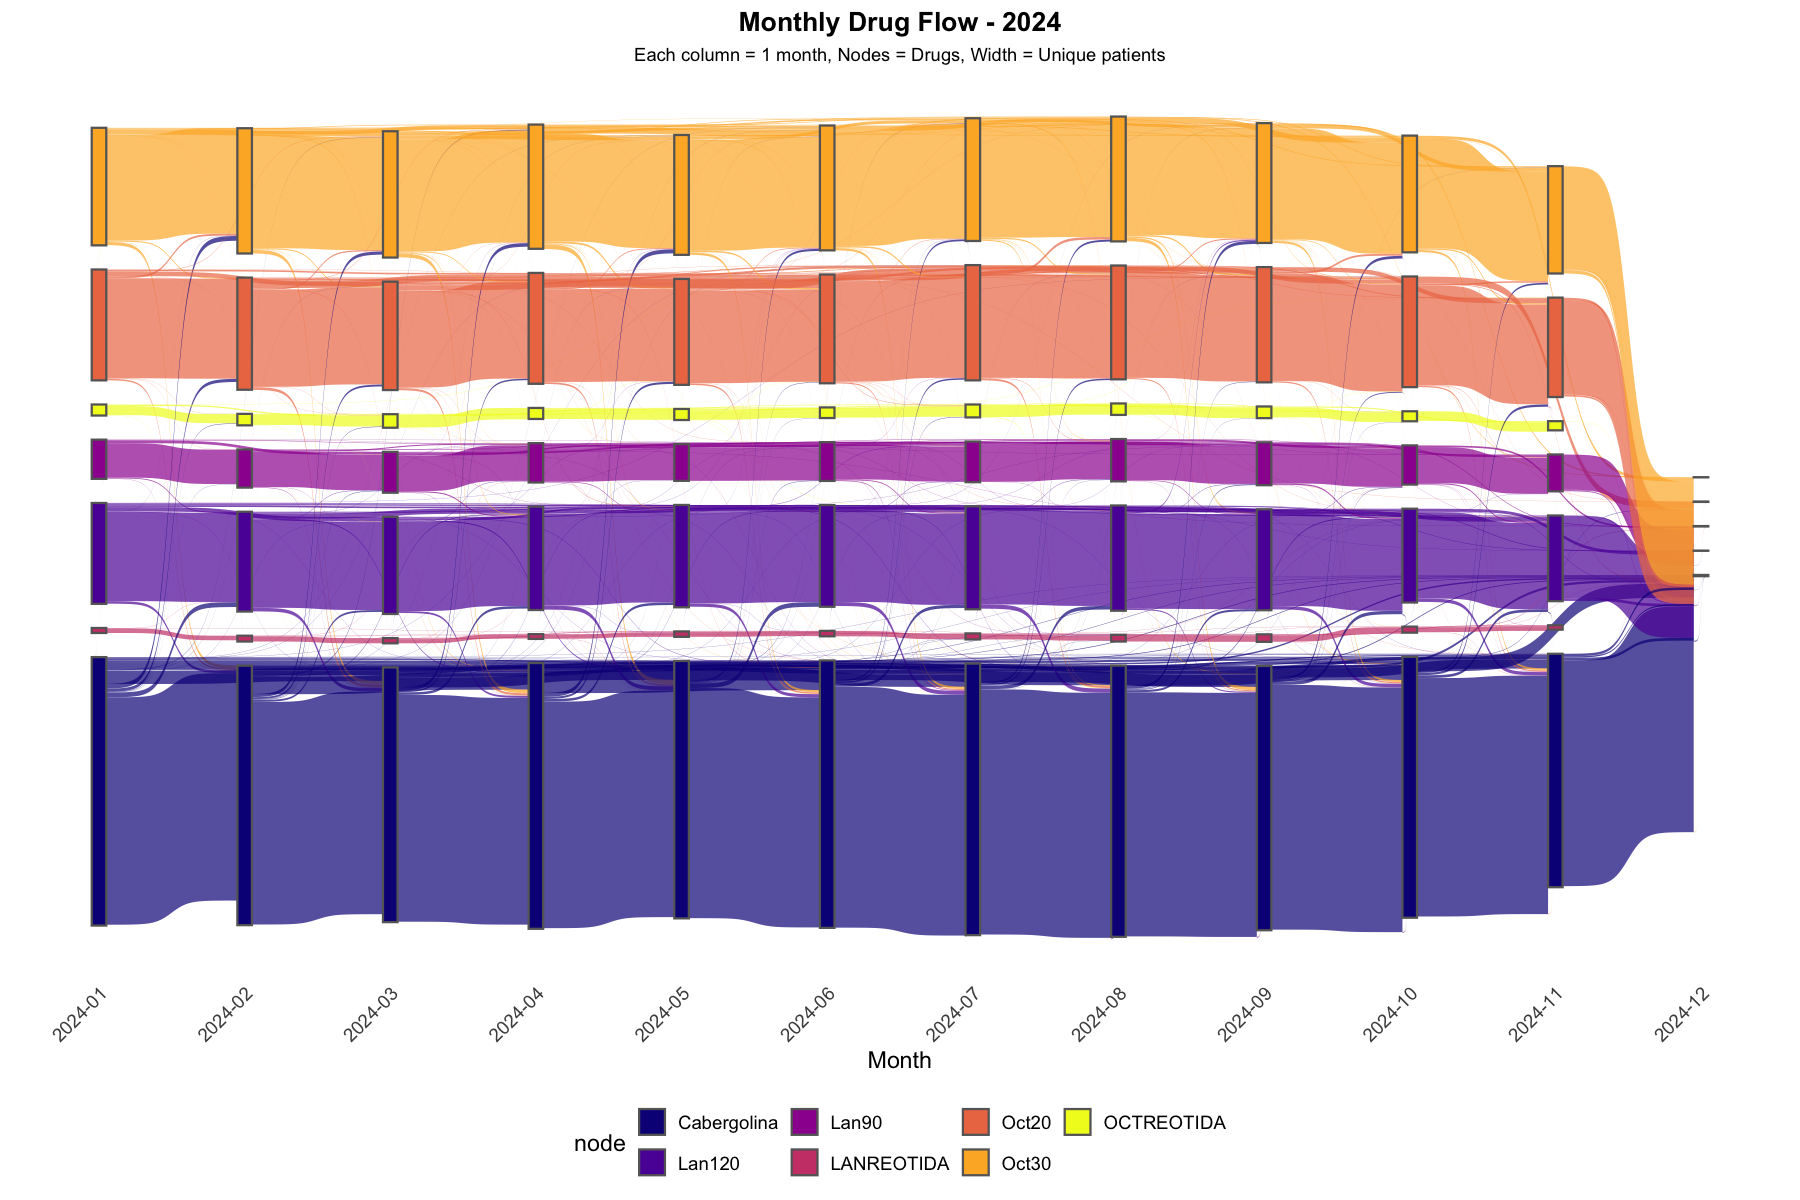

In [33]:
# Sankey - Fluxo de Medicamentos Mês a Mês
library(tidyverse)
library(ggsankey)

cat("=== DIAGRAMA DE SANKEY - FORÇANDO ORDENAÇÃO E FLUXO ===\n")

# 1. Preparar dados com pacientes e medicamentos por mês (inalterado)
dados <- dados_unificados %>%
  filter(!is.na(AP_PRIPAL) & !is.na(AP_CNSPCN)) %>%
  mutate(
    medicamento = recode(as.character(AP_PRIPAL), !!!codigo_nomes),
    mes = format(AP_CMP, "%Y-%m"),
    med_nome = case_when(
      str_detect(medicamento, "CABERGOLINA") ~ "Cabergolina",
      str_detect(medicamento, "LANREOTIDA 120") ~ "Lan120",
      str_detect(medicamento, "LANREOTIDA 90") ~ "Lan90",
      str_detect(medicamento, "OCTREOTIDA LAR 30") ~ "Oct30",
      str_detect(medicamento, "OCTREOTIDA LAR 20") ~ "Oct20",
      TRUE ~ substr(medicamento, 1, 10)
    )
  ) %>%
  filter(!is.na(medicamento)) %>%
  select(AP_CNSPCN, mes, med_nome) %>%
  distinct() %>%
  arrange(AP_CNSPCN, mes)

cat("Total registros:", nrow(dados), "\n")

# 2. Criar a tabela de Transições Mês-a-Mês (Flow Table)
trans <- dados %>%
  group_by(AP_CNSPCN) %>%
  arrange(mes) %>%
  mutate(
    mes_proximo = lead(mes),
    med_proximo = lead(med_nome)
  ) %>%
  ungroup() %>%
  filter(!is.na(mes_proximo)) %>%
  select(AP_CNSPCN, mes_atual = mes, mes_proximo, med_atual = med_nome, med_proximo)

cat("Total de transições:", nrow(trans), "\n")

# 3. Agregar fluxos, formatar e FORÇAR A ORDENAÇÃO
dados_sankey <- trans %>%
  group_by(mes_atual, med_atual, mes_proximo, med_proximo) %>%
  summarise(value = n_distinct(AP_CNSPCN), .groups = "drop") %>%
  arrange(mes_atual, mes_proximo) %>%
  
  # Renomear colunas para o formato Sankey
  select(
    x = mes_atual,
    next_x = mes_proximo, 
    node = med_atual,
    next_node = med_proximo,
    value = value
  ) %>%
  
  # ADIÇÃO CHAVE: Forçar 'x' e 'next_x' a serem fatores ordenados (meses)
  # Isso garante que a ordem no eixo X seja respeitada e o fluxo seja traçado sequencialmente.
  mutate(
    x = factor(x, levels = unique(dados$mes)),
    next_x = factor(next_x, levels = unique(dados$mes))
  )

cat("Fluxos únicos (pronto para plotar):", nrow(dados_sankey), "\n")
cat("\nPreparando dados para Sankey...\n")
print(head(dados_sankey, 10))

# 4. Plotar Sankey
cat("\nPlotando Sankey com", length(unique(dados_sankey$x)), "colunas (meses)...\n")

p <- ggplot(dados_sankey, aes(x = x, 
                              next_x = next_x,
                              node = node,
                              next_node = next_node,
                              fill = node,
                              value = value)) +
  # Se o fluxo for muito pequeno (valor < 1), ele não aparece. 
  # O 'value' é a espessura. Com n_distinct(AP_CNSPCN), deve ser >= 1.
  geom_sankey(flow.alpha = 0.7, node.color = "gray40", smooth = 8) +
  scale_fill_viridis_d(option = "plasma") +
  theme_sankey(base_size = 14) +
  labs(
    title = "Monthly Drug Flow - 2024",
    x = "Month",
    subtitle = "Each column = 1 month, Nodes = Drugs, Width = Unique patients"
  ) +
  theme(
    plot.title = element_text(face = "bold", size = 16, hjust = 0.5),
    plot.subtitle = element_text(size = 11, hjust = 0.5),
    legend.position = "bottom",
    axis.text.x = element_text(angle = 45, hjust = 1)
  )

print(p)
cat("\n✅ DIAGRAMA DE SANKEY CRIADO COM AS LINHAS DE FLUXO (Ordenação forçada aplicada)!\n")

In [34]:
# Certifique-se de que o pacote 'writexl' esteja instalado:
# install.packages("writexl")
library(writexl)
library(ggplot2) # Necessário para o ggsave

# --- CONFIGURAÇÕES DE SALVAMENTO ---

# 1. Definir o caminho de destino (Mantenha o final com /)
diretorio_destino <- "../data/processed/"

# 2. Gerar a data de hoje no formato YYYYMMDD_
# Usamos Sys.Date() para pegar a data atual do sistema.
data_hoje <- format(Sys.Date(), "%Y%m%d_")

# 3. Definir o nome base dos arquivos
nome_base <- "acromegalia_diagrama_sankey"
nome_tabela <- paste0(data_hoje, nome_base, "_tabela.xlsx")
nome_grafico <- paste0(data_hoje, nome_base, ".png")

# 4. Criar o caminho completo dos arquivos
caminho_tabela <- file.path(diretorio_destino, nome_tabela)
caminho_grafico <- file.path(diretorio_destino, nome_grafico)


# --- SALVAR O ARQUIVO EXCEL ---

cat("\nSalvando tabela de fluxo em:", caminho_tabela, "\n")
tryCatch({
  write_xlsx(dados_sankey, path = caminho_tabela)
  cat("✅ Tabela de Sankey salva com sucesso no formato .xlsx!\n")
}, error = function(e) {
  cat("❌ ERRO ao salvar a tabela Excel: Verifique se o pacote 'writexl' está instalado e se o diretório existe.\n")
  print(e)
})


# --- SALVAR O GRÁFICO ---

cat("\nSalvando diagrama de Sankey em:", caminho_grafico, "\n")
tryCatch({
  # Usamos ggsave para salvar o objeto ggplot (p)
  # Definimos largura e altura para garantir a qualidade
  ggsave(
    filename = caminho_grafico,
    plot = p,
    width = 15,    # Ajuste se o gráfico estiver muito estreito/largo
    height = 10,   # Ajuste se o gráfico estiver muito baixo/alto
    units = "in",  # Unidades em polegadas
    dpi = 300      # Alta resolução
  )
  cat("✅ Diagrama de Sankey salvo com sucesso no formato .png!\n")
}, error = function(e) {
  cat("❌ ERRO ao salvar o gráfico: Verifique se o diretório existe e se o objeto 'p' foi gerado corretamente.\n")
  print(e)
})

cat("\n--- FIM DO PROCESSO DE SALVAMENTO ---\n")


Salvando tabela de fluxo em: ../data/processed//20261013_acromegalia_diagrama_sankey_tabela.xlsx 
✅ Tabela de Sankey salva com sucesso no formato .xlsx!

Salvando diagrama de Sankey em: ../data/processed//20261013_acromegalia_diagrama_sankey.png 
✅ Diagrama de Sankey salvo com sucesso no formato .png!

--- FIM DO PROCESSO DE SALVAMENTO ---


#### 7.4.2 - Gráfico Alluvial de Fluxo de Medicamentos por Paciente

> **Terceira revisão:** este gráfico é exploratório (por dose) e **não** é a Figura 2. Ele mantém as limitações apontadas no item 4c (um medicamento por paciente-mês via `first()` e cor das faixas pelo mês de janeiro). A versão corrigida da Figura 2 está na seção 7.4.4. Este gráfico não é mais salvo em disco.

=== GRÁFICO ALLUVIAL - FLUXO DE MEDICAMENTOS POR PACIENTE ===


Loading required package: ggalluvial



Total de registros para alluvial: 96 
Meses únicos: 12 
Medicamentos únicos: 8 

Medicamentos e cores atribuídas:
  1. CABERGOLINA 0,5 MG: #E64B35
  2. LANREOTIDA 120 MG INJETÁVEL: #4DBBD5
  3. LANREOTIDA 60 MG INJETÁVEL: #00A087
  4. LANREOTIDA 90 MG INJETÁVEL: #3C5488
  5. OCTREOTIDA 0,1 MG/ML INJETÁVEL: #F39B7F
  6. OCTREOTIDA LAR 10 MG INJETÁVEL: #8491B4
  7. OCTREOTIDA LAR 20 MG INJETÁVEL: #91D1C2
  8. OCTREOTIDA LAR 30 MG INJETÁVEL: #DC0000

Preparando dados para alluvial...
Pacientes únicos no dataset alluvial: 4231 

Plotando gráfico alluvial...


Warning message in geom_alluvium(aes(fill = Janeiro), alpha = 0.65, width = 1/12, :
“Ignoring unknown parameters: `smooth`”
Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
“Some strata appear at multiple axes.”
Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
“Some strata appear at multiple axes.”



✅ GRÁFICO ALLUVIAL CRIADO COM SUCESSO!

--- FIM DO PROCESSO DE CRIAÇÃO DO GRÁFICO ALLUVIAL ---


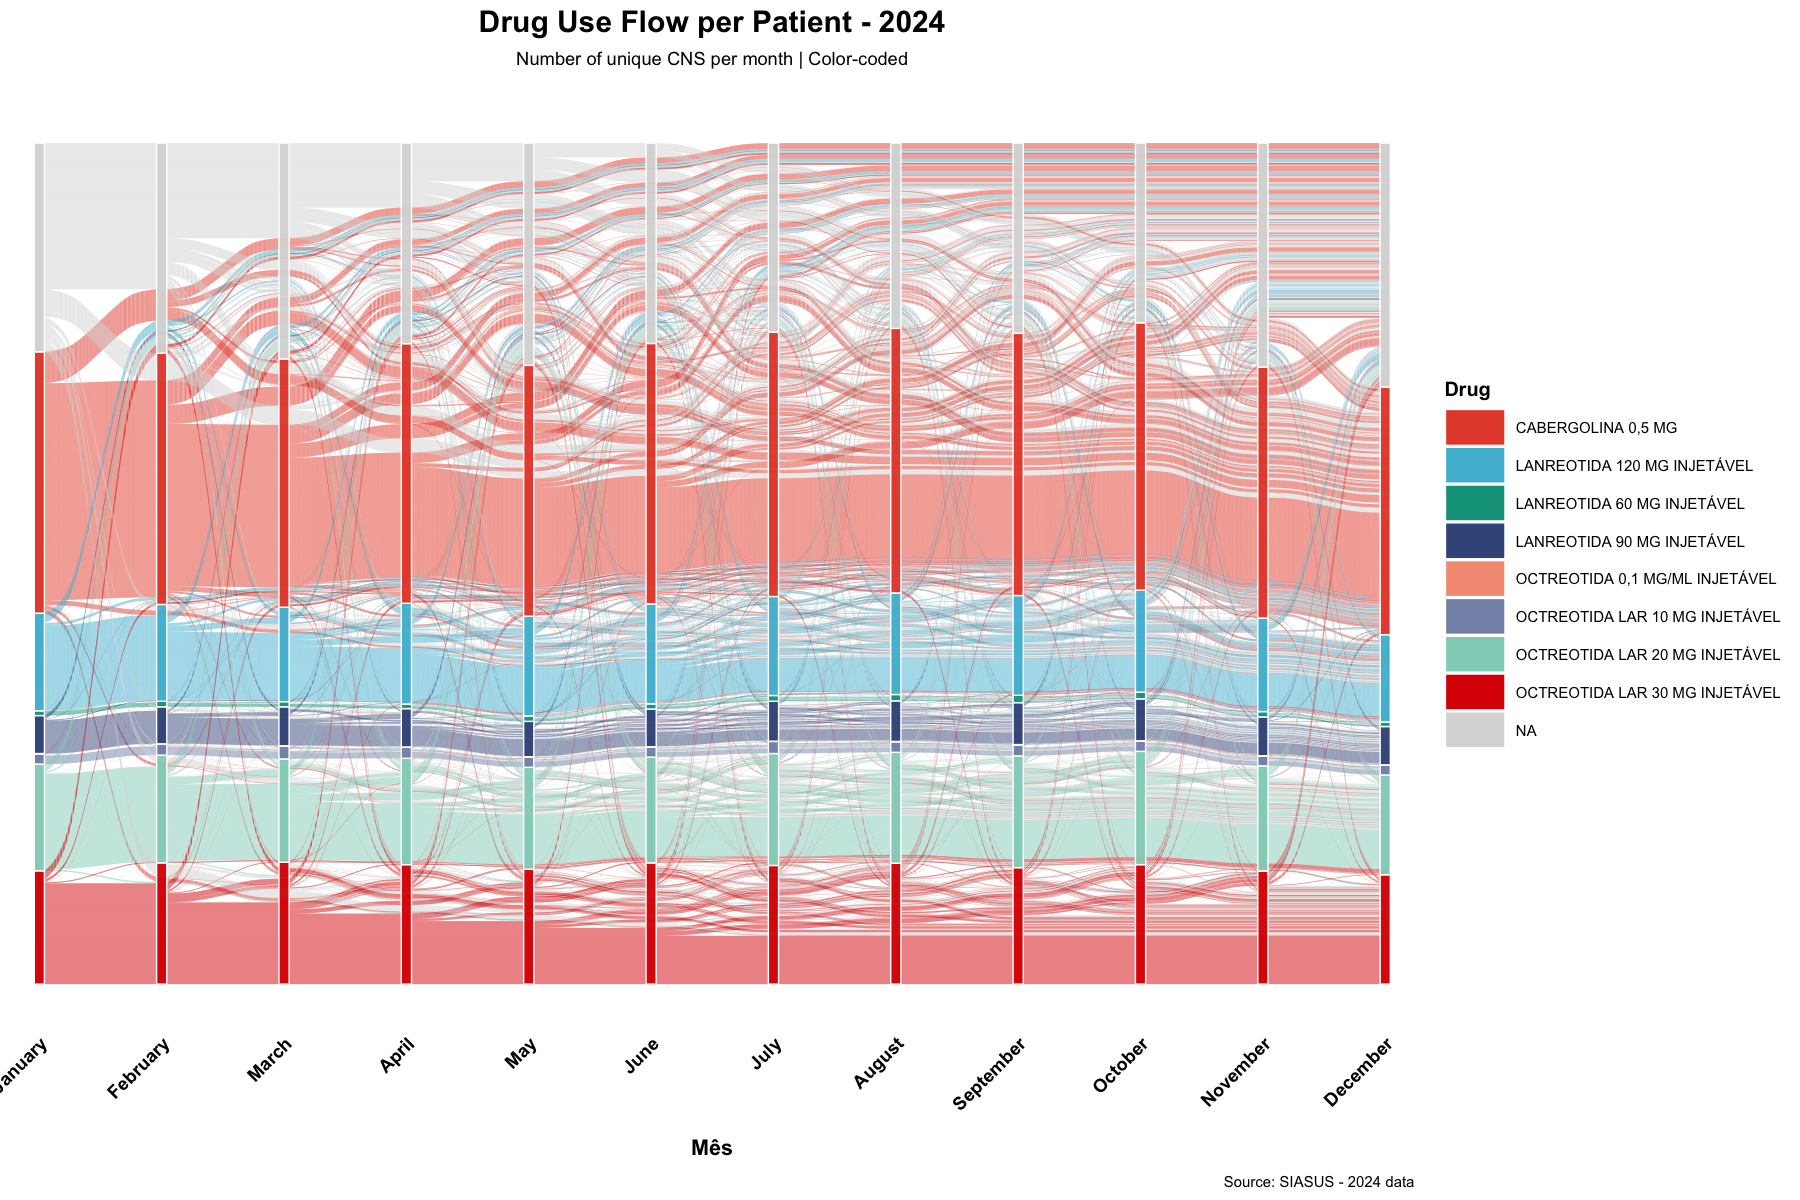

In [35]:
# Gráfico Alluvial - Fluxo de Medicamentos por Paciente
# Contando CNS únicos por mês (janeiro a dezembro de 2024)

cat("=== GRÁFICO ALLUVIAL - FLUXO DE MEDICAMENTOS POR PACIENTE ===\n")

# Carregar pacote ggalluvial se necessário
if (!require(ggalluvial)) {
  install.packages("ggalluvial")
  library(ggalluvial)
}

# Preparar dados: contar CNS únicos por mês e medicamento padronizado
dados_alluvial <- dados_unificados %>%
  filter(!is.na(AP_PRIPAL) & !is.na(AP_CNSPCN)) %>%
  filter(AP_CMP >= as.Date("2024-01-01") & AP_CMP <= as.Date("2024-12-31")) %>%
  mutate(
    medicamento = recode(as.character(AP_PRIPAL), !!!codigo_nomes),
    mes = format(AP_CMP, "%Y-%m"),
    mes_num = as.numeric(format(AP_CMP, "%m"))
  ) %>%
  filter(!is.na(medicamento)) %>%
  # Padronizar nomes dos medicamentos (usar nomes completos)
  mutate(
    medicamento_padronizado = case_when(
      str_detect(medicamento, "CABERGOLINA") ~ "CABERGOLINA 0,5 MG",
      str_detect(medicamento, "LANREOTIDA 120") ~ "LANREOTIDA 120 MG INJETÁVEL",
      str_detect(medicamento, "LANREOTIDA 90") ~ "LANREOTIDA 90 MG INJETÁVEL",
      str_detect(medicamento, "LANREOTIDA 60") ~ "LANREOTIDA 60 MG INJETÁVEL",
      str_detect(medicamento, "OCTREOTIDA LAR 30") ~ "OCTREOTIDA LAR 30 MG INJETÁVEL",
      str_detect(medicamento, "OCTREOTIDA LAR 20") ~ "OCTREOTIDA LAR 20 MG INJETÁVEL",
      str_detect(medicamento, "OCTREOTIDA LAR 10") ~ "OCTREOTIDA LAR 10 MG INJETÁVEL",
      str_detect(medicamento, "OCTREOTIDA 0,1") ~ "OCTREOTIDA 0,1 MG/ML INJETÁVEL",
      TRUE ~ medicamento
    )
  ) %>%
  # Contar CNS únicos por mês e medicamento
  group_by(mes, mes_num, medicamento_padronizado) %>%
  summarise(
    quantidade_cns = n_distinct(AP_CNSPCN),
    .groups = "drop"
  ) %>%
  # Garantir ordem correta dos meses
  arrange(mes_num, medicamento_padronizado)

cat("Total de registros para alluvial:", nrow(dados_alluvial), "\n")
cat("Meses únicos:", length(unique(dados_alluvial$mes)), "\n")
cat("Medicamentos únicos:", length(unique(dados_alluvial$medicamento_padronizado)), "\n")

# Criar paleta de cores para cada medicamento
medicamentos_unicos <- sort(unique(dados_alluvial$medicamento_padronizado))
n_medicamentos <- length(medicamentos_unicos)

# Paleta de cores distinta e harmoniosa
cores_medicamentos <- c(
  "#E64B35", "#4DBBD5", "#00A087", "#3C5488", "#F39B7F",
  "#8491B4", "#91D1C2", "#DC0000", "#7E6148", "#B09C85"
)

# Ajustar tamanho da paleta se necessário
if (n_medicamentos > length(cores_medicamentos)) {
  cores_medicamentos <- colorRampPalette(cores_medicamentos)(n_medicamentos)
} else {
  cores_medicamentos <- cores_medicamentos[1:n_medicamentos]
}

names(cores_medicamentos) <- medicamentos_unicos

cat("\nMedicamentos e cores atribuídas:\n")
for (i in 1:length(medicamentos_unicos)) {
  cat(sprintf("  %d. %s: %s\n", i, medicamentos_unicos[i], cores_medicamentos[i]))
}

# Preparar dados no formato adequado para alluvial
# Para cada paciente, criar uma sequência de medicamentos por mês
dados_pacientes_mes <- dados_unificados %>%
  filter(!is.na(AP_PRIPAL) & !is.na(AP_CNSPCN)) %>%
  filter(AP_CMP >= as.Date("2024-01-01") & AP_CMP <= as.Date("2024-12-31")) %>%
  mutate(
    medicamento = recode(as.character(AP_PRIPAL), !!!codigo_nomes),
    mes = format(AP_CMP, "%Y-%m"),
    mes_num = as.numeric(format(AP_CMP, "%m"))
  ) %>%
  filter(!is.na(medicamento)) %>%
  mutate(
    medicamento_padronizado = case_when(
      str_detect(medicamento, "CABERGOLINA") ~ "CABERGOLINA 0,5 MG",
      str_detect(medicamento, "LANREOTIDA 120") ~ "LANREOTIDA 120 MG INJETÁVEL",
      str_detect(medicamento, "LANREOTIDA 90") ~ "LANREOTIDA 90 MG INJETÁVEL",
      str_detect(medicamento, "LANREOTIDA 60") ~ "LANREOTIDA 60 MG INJETÁVEL",
      str_detect(medicamento, "OCTREOTIDA LAR 30") ~ "OCTREOTIDA LAR 30 MG INJETÁVEL",
      str_detect(medicamento, "OCTREOTIDA LAR 20") ~ "OCTREOTIDA LAR 20 MG INJETÁVEL",
      str_detect(medicamento, "OCTREOTIDA LAR 10") ~ "OCTREOTIDA LAR 10 MG INJETÁVEL",
      str_detect(medicamento, "OCTREOTIDA 0,1") ~ "OCTREOTIDA 0,1 MG/ML INJETÁVEL",
      TRUE ~ medicamento
    )
  ) %>%
  select(AP_CNSPCN, mes, mes_num, medicamento_padronizado) %>%
  distinct() %>%
  arrange(AP_CNSPCN, mes_num)

# Criar formato wide: uma linha por paciente com colunas para cada mês
dados_alluvial_wide <- dados_pacientes_mes %>%
  # Para cada paciente, pegar o medicamento de cada mês (se houver múltiplos, pegar o primeiro)
  group_by(AP_CNSPCN, mes_num) %>%
  summarise(medicamento = first(medicamento_padronizado), .groups = "drop") %>%
  # Transformar em formato wide
  pivot_wider(
    names_from = mes_num,
    values_from = medicamento,
    names_prefix = "Mes_",
    values_fill = NA
  ) %>%
  # Renomear colunas com nomes dos meses
  rename(
    Janeiro = Mes_1, Fevereiro = Mes_2, Março = Mes_3, Abril = Mes_4,
    Maio = Mes_5, Junho = Mes_6, Julho = Mes_7, Agosto = Mes_8,
    Setembro = Mes_9, Outubro = Mes_10, Novembro = Mes_11, Dezembro = Mes_12
  ) %>%
  # Remover pacientes que não têm medicamento em nenhum mês
  filter(!if_all(c(Janeiro, Fevereiro, Março, Abril, Maio, Junho,
                   Julho, Agosto, Setembro, Outubro, Novembro, Dezembro), is.na))

cat("\nPreparando dados para alluvial...\n")
cat("Pacientes únicos no dataset alluvial:", nrow(dados_alluvial_wide), "\n")

# Plotar gráfico alluvial
cat("\nPlotando gráfico alluvial...\n")

# Criar gráfico alluvial limpo - sem labels, apenas cores nos nós e fluxos
p_alluvial <- ggplot(dados_alluvial_wide,
                     aes(axis1 = Janeiro, axis2 = Fevereiro, axis3 = Março,
                         axis4 = Abril, axis5 = Maio, axis6 = Junho,
                         axis7 = Julho, axis8 = Agosto, axis9 = Setembro,
                         axis10 = Outubro, axis11 = Novembro, axis12 = Dezembro)) +
  # Fluxos alluviais com cor baseada no medicamento do primeiro mês
  geom_alluvium(aes(fill = Janeiro), alpha = 0.65, width = 1/12, 
                curve_type = "spline", smooth = 8) +
  # Nós (stratum) coloridos pelo medicamento - cada nó mostra a cor do medicamento
  # Usar fill baseado no valor do stratum (medicamento)
  geom_stratum(aes(fill = after_stat(stratum)), width = 1/12, 
              color = "white", size = 0.4, alpha = 0.95) +
  # SEM labels - completamente removido
  scale_x_discrete(limits = c("Janeiro", "Fevereiro", "Março", "Abril", "Maio", "Junho",
                              "Julho", "Agosto", "Setembro", "Outubro", "Novembro", "Dezembro"),
                   labels = c("January", "February", "March", "April", "May", "June",
                              "July", "August", "September", "October", "November", "December"),
                   expand = c(0.02, 0.02)) +
  scale_fill_manual(values = cores_medicamentos, name = "Drug", 
                    na.value = "grey85", 
                    guide = guide_legend(ncol = 1, 
                                        override.aes = list(alpha = 0.9, size = 0.5),
                                        title.position = "top")) +
  labs(
    title = "Drug Use Flow per Patient - 2024",
    subtitle = "Number of unique CNS per month | Color-coded",
    x = "Mês",
    y = "",
    fill = "Medicamento",
    caption = "Source: SIASUS - 2024 data"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    plot.title = element_text(size = 18, face = "bold", hjust = 0.5, margin = margin(b = 8)),
    plot.subtitle = element_text(size = 11, hjust = 0.5, margin = margin(b = 20)),
    axis.text.x = element_text(angle = 45, hjust = 1, size = 11, face = "bold", color = "black"),
    axis.text.y = element_blank(),
    axis.title.x = element_text(size = 13, face = "bold", margin = margin(t = 15)),
    axis.title.y = element_blank(),
    axis.ticks = element_blank(),
    legend.position = "right",
    legend.text = element_text(size = 9),
    legend.title = element_text(size = 12, face = "bold"),
    legend.key.size = unit(1.3, "cm"),
    legend.key.height = unit(0.8, "cm"),
    panel.grid = element_blank(),
    plot.caption = element_text(size = 9, hjust = 1, margin = margin(t = 10)),
    plot.background = element_rect(fill = "white", color = NA),
    panel.background = element_rect(fill = "white", color = NA)
  )

print(p_alluvial)

cat("\n✅ GRÁFICO ALLUVIAL CRIADO COM SUCESSO!\n")

# Terceira revisão: gráfico exploratório, não é mais salvo em disco (ver 7.4.4)

cat("\n--- FIM DO PROCESSO DE CRIAÇÃO DO GRÁFICO ALLUVIAL ---\n")

#### 7.4.3 - Gráfico Alluvial de Fluxo de Medicamentos (Apenas Períodos de Uso)

> **Terceira revisão:** este gráfico é exploratório (por dose) e **não** é a Figura 2. Ele mantém as limitações apontadas no item 4c (um medicamento por paciente-mês via `first()` e cor das faixas pelo mês de janeiro). A versão corrigida da Figura 2 está na seção 7.4.4. Este gráfico não é mais salvo em disco.

=== 7.4.3 - GRÁFICO ALLUVIAL - Apenas meses com uso ===
Pacientes únicos no dataset alluvial (apenas uso): 4231 


Warning message in geom_alluvium(aes(fill = Janeiro), alpha = 0.65, width = 1/12, :
“Ignoring unknown parameters: `smooth`”
Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
“Some strata appear at multiple axes.”
Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
“Some strata appear at multiple axes.”



✅ GRÁFICO ALLUVIAL 7.4.3 CRIADO COM SUCESSO!

--- FIM DO PROCESSO DE CRIAÇÃO DO GRÁFICO ALLUVIAL 7.4.3 ---


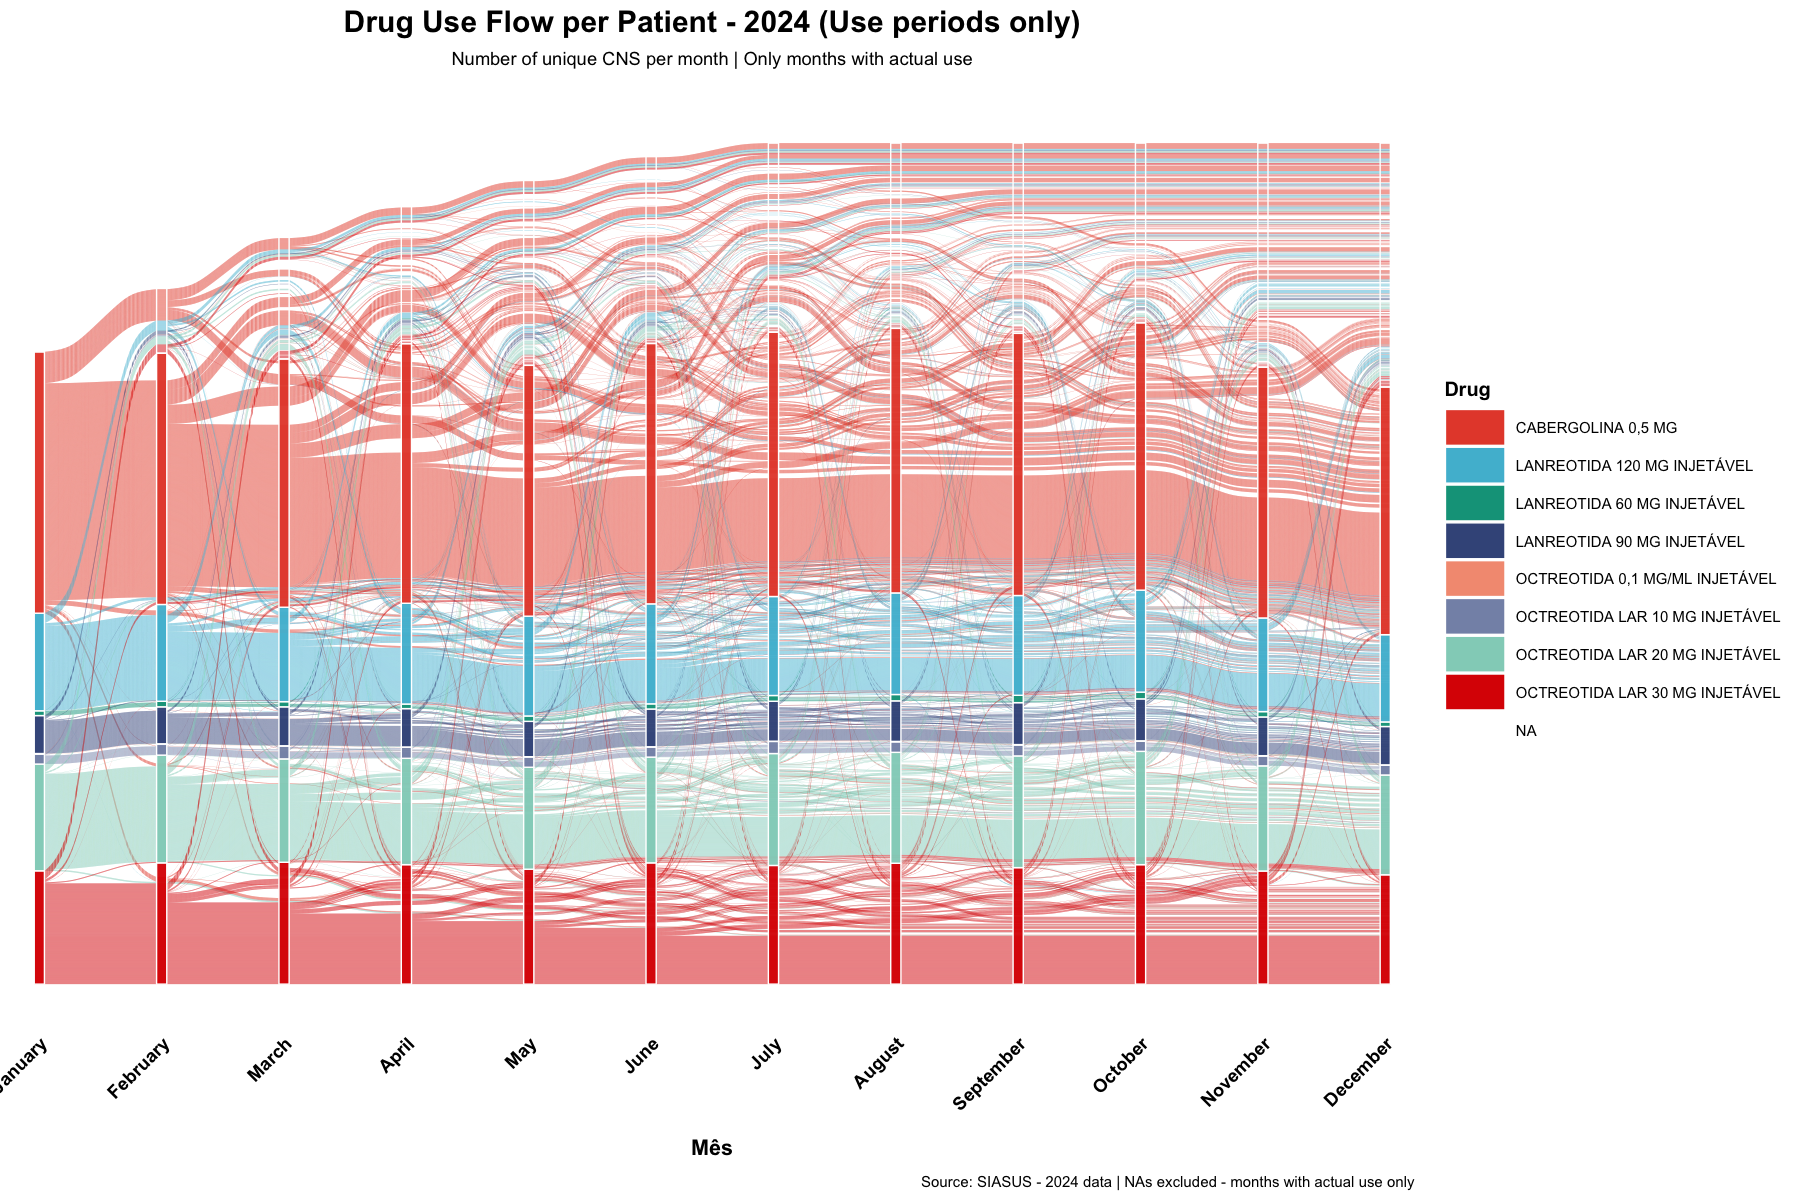

In [36]:
cat("=== 7.4.3 - GRÁFICO ALLUVIAL - Apenas meses com uso ===\n")

# Preparar dados apenas com meses em que o paciente estava usando medicamento
# Remover COMPLETAMENTE os NAs - considerar apenas períodos de uso efetivo
# Se um CNS não estava usando antes ou deixou depois, contar apenas os meses de uso
dados_alluvial_uso <- dados_pacientes_mes %>%
  # Filtrar apenas registros válidos (sem NA) - apenas meses com uso
  filter(!is.na(medicamento_padronizado)) %>%
  # Para cada paciente, pegar o medicamento de cada mês em que estava usando
  group_by(AP_CNSPCN, mes_num) %>%
  summarise(medicamento = first(medicamento_padronizado), .groups = "drop") %>%
  # Transformar em formato wide - NÃO preencher com NA, deixar vazio onde não há uso
  pivot_wider(
    names_from = mes_num,
    values_from = medicamento,
    names_prefix = "Mes_"
    # NÃO usar values_fill = NA - deixar como NULL onde não há medicamento
  ) %>%
  # Renomear colunas com nomes dos meses
  rename(
    Janeiro = Mes_1, Fevereiro = Mes_2, Março = Mes_3, Abril = Mes_4,
    Maio = Mes_5, Junho = Mes_6, Julho = Mes_7, Agosto = Mes_8,
    Setembro = Mes_9, Outubro = Mes_10, Novembro = Mes_11, Dezembro = Mes_12
  ) %>%
  # Remover pacientes que não têm medicamento em nenhum mês
  filter(!if_all(c(Janeiro, Fevereiro, Março, Abril, Maio, Junho,
                   Julho, Agosto, Setembro, Outubro, Novembro, Dezembro), is.na)) %>%
  # Filtrar linhas onde há pelo menos um mês com uso
  filter(rowSums(!is.na(select(., Janeiro:Dezembro))) > 0)
  # Manter apenas valores válidos (não NA) - os NAs serão ignorados pelo ggalluvial
  # Não converter para string vazia, deixar como NA mas garantir que não apareçam como categoria

cat("Pacientes únicos no dataset alluvial (apenas uso):", nrow(dados_alluvial_uso), "\n")

# Criar segundo gráfico alluvial - apenas meses com uso
p_alluvial_uso <- ggplot(dados_alluvial_uso,
                         aes(axis1 = Janeiro, axis2 = Fevereiro, axis3 = Março,
                             axis4 = Abril, axis5 = Maio, axis6 = Junho,
                             axis7 = Julho, axis8 = Agosto, axis9 = Setembro,
                             axis10 = Outubro, axis11 = Novembro, axis12 = Dezembro)) +
  # Fluxos alluviais com cor baseada no medicamento do primeiro mês com uso
  geom_alluvium(aes(fill = Janeiro), alpha = 0.65, width = 1/12, 
                curve_type = "spline", smooth = 8) +
  # Nós (stratum) coloridos pelo medicamento - apenas onde há uso
  geom_stratum(aes(fill = after_stat(stratum)), width = 1/12, 
              color = "white", size = 0.4, alpha = 0.95) +
  # SEM labels
  scale_x_discrete(limits = c("Janeiro", "Fevereiro", "Março", "Abril", "Maio", "Junho",
                              "Julho", "Agosto", "Setembro", "Outubro", "Novembro", "Dezembro"),
                   labels = c("January", "February", "March", "April", "May", "June",
                              "July", "August", "September", "October", "November", "December"),
                   expand = c(0.02, 0.02)) +
  scale_fill_manual(values = cores_medicamentos, name = "Drug", 
                    na.value = NA,  # NAs não devem aparecer
                    guide = guide_legend(ncol = 1, 
                                        override.aes = list(alpha = 0.9, size = 0.5),
                                        title.position = "top")) +
  labs(
    title = "Drug Use Flow per Patient - 2024 (Use periods only)",
    subtitle = "Number of unique CNS per month | Only months with actual use",
    x = "Mês",
    y = "",
    fill = "Medicamento",
    caption = "Source: SIASUS - 2024 data | NAs excluded - months with actual use only"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    plot.title = element_text(size = 18, face = "bold", hjust = 0.5, margin = margin(b = 8)),
    plot.subtitle = element_text(size = 11, hjust = 0.5, margin = margin(b = 20)),
    axis.text.x = element_text(angle = 45, hjust = 1, size = 11, face = "bold", color = "black"),
    axis.text.y = element_blank(),
    axis.title.x = element_text(size = 13, face = "bold", margin = margin(t = 15)),
    axis.title.y = element_blank(),
    axis.ticks = element_blank(),
    legend.position = "right",
    legend.text = element_text(size = 9),
    legend.title = element_text(size = 12, face = "bold"),
    legend.key.size = unit(1.3, "cm"),
    legend.key.height = unit(0.8, "cm"),
    panel.grid = element_blank(),
    plot.caption = element_text(size = 9, hjust = 1, margin = margin(t = 10)),
    plot.background = element_rect(fill = "white", color = NA),
    panel.background = element_rect(fill = "white", color = NA)
  )

print(p_alluvial_uso)

cat("\n✅ GRÁFICO ALLUVIAL 7.4.3 CRIADO COM SUCESSO!\n")

# Terceira revisão: gráfico exploratório, não é mais salvo em disco (ver 7.4.4)

cat("\n--- FIM DO PROCESSO DE CRIAÇÃO DO GRÁFICO ALLUVIAL 7.4.3 ---\n")

#### 7.4.4 - Figura 2: dispensação mensal registrada, por princípio ativo (corrigida na terceira revisão, item 4)

O que a figura representa e o que mudou:
- **Dispensação mensal registrada**: cada eixo é uma competência (`AP_CMP`) de 2024; a categoria de um paciente num mês é o conjunto de princípios ativos com registro de dispensação naquele mês. **Não** é estimada cobertura de tratamento: nenhum período de cobertura é propagado para meses seguintes.
- **"No dispensing record"** substitui o antigo "NA": meses sem nenhum registro de dispensação para o paciente.
- **Combinações**: quando há mais de um princípio ativo no mesmo paciente-mês, a combinação é mantida como categoria própria (ex.: "Octreotide + Cabergoline"), em vez de `first()` descartar um deles.
- **Cor das faixas**: cada faixa entre dois meses é colorida pela categoria do paciente no mês de origem (`geom_flow(aes(fill = categoria))`), e não mais pelo valor de janeiro.
- N = pacientes da coorte final (CNS válido).


=== 7.4.4 - FIGURA 2: DISPENSAÇÃO MENSAL REGISTRADA ===
# A tibble: 7 × 13
  categoria      January February March April   May  June  July August September
  <chr>            <int>    <int> <int> <int> <int> <int> <int>  <int>     <int>
1 Cabergoline       1311     1261  1247  1303  1261  1309  1327   1329      1316
2 Octreotide        1160     1208  1198  1193  1143  1192  1220   1218      1204
3 Lanreotide         704      701   693   721   704   715   724    743       745
4 Lanreotide + …       3        2     5     3     3     4     4      5         5
5 Octreotide + …       3        2     2     2     2     3     4      4         3
6 Octreotide + …       0        0     0     0     0     0     1      0         1
7 No dispensing…    1050     1057  1086  1009  1118  1008   951    932       957
# ℹ 3 more variables: October <int>, November <int>, December <int>
Pacientes-mês com combinação de princípios ativos: 93 | pacientes: 32 
✅ Figura 2 salva em: ../resultados/third_review/20261013_

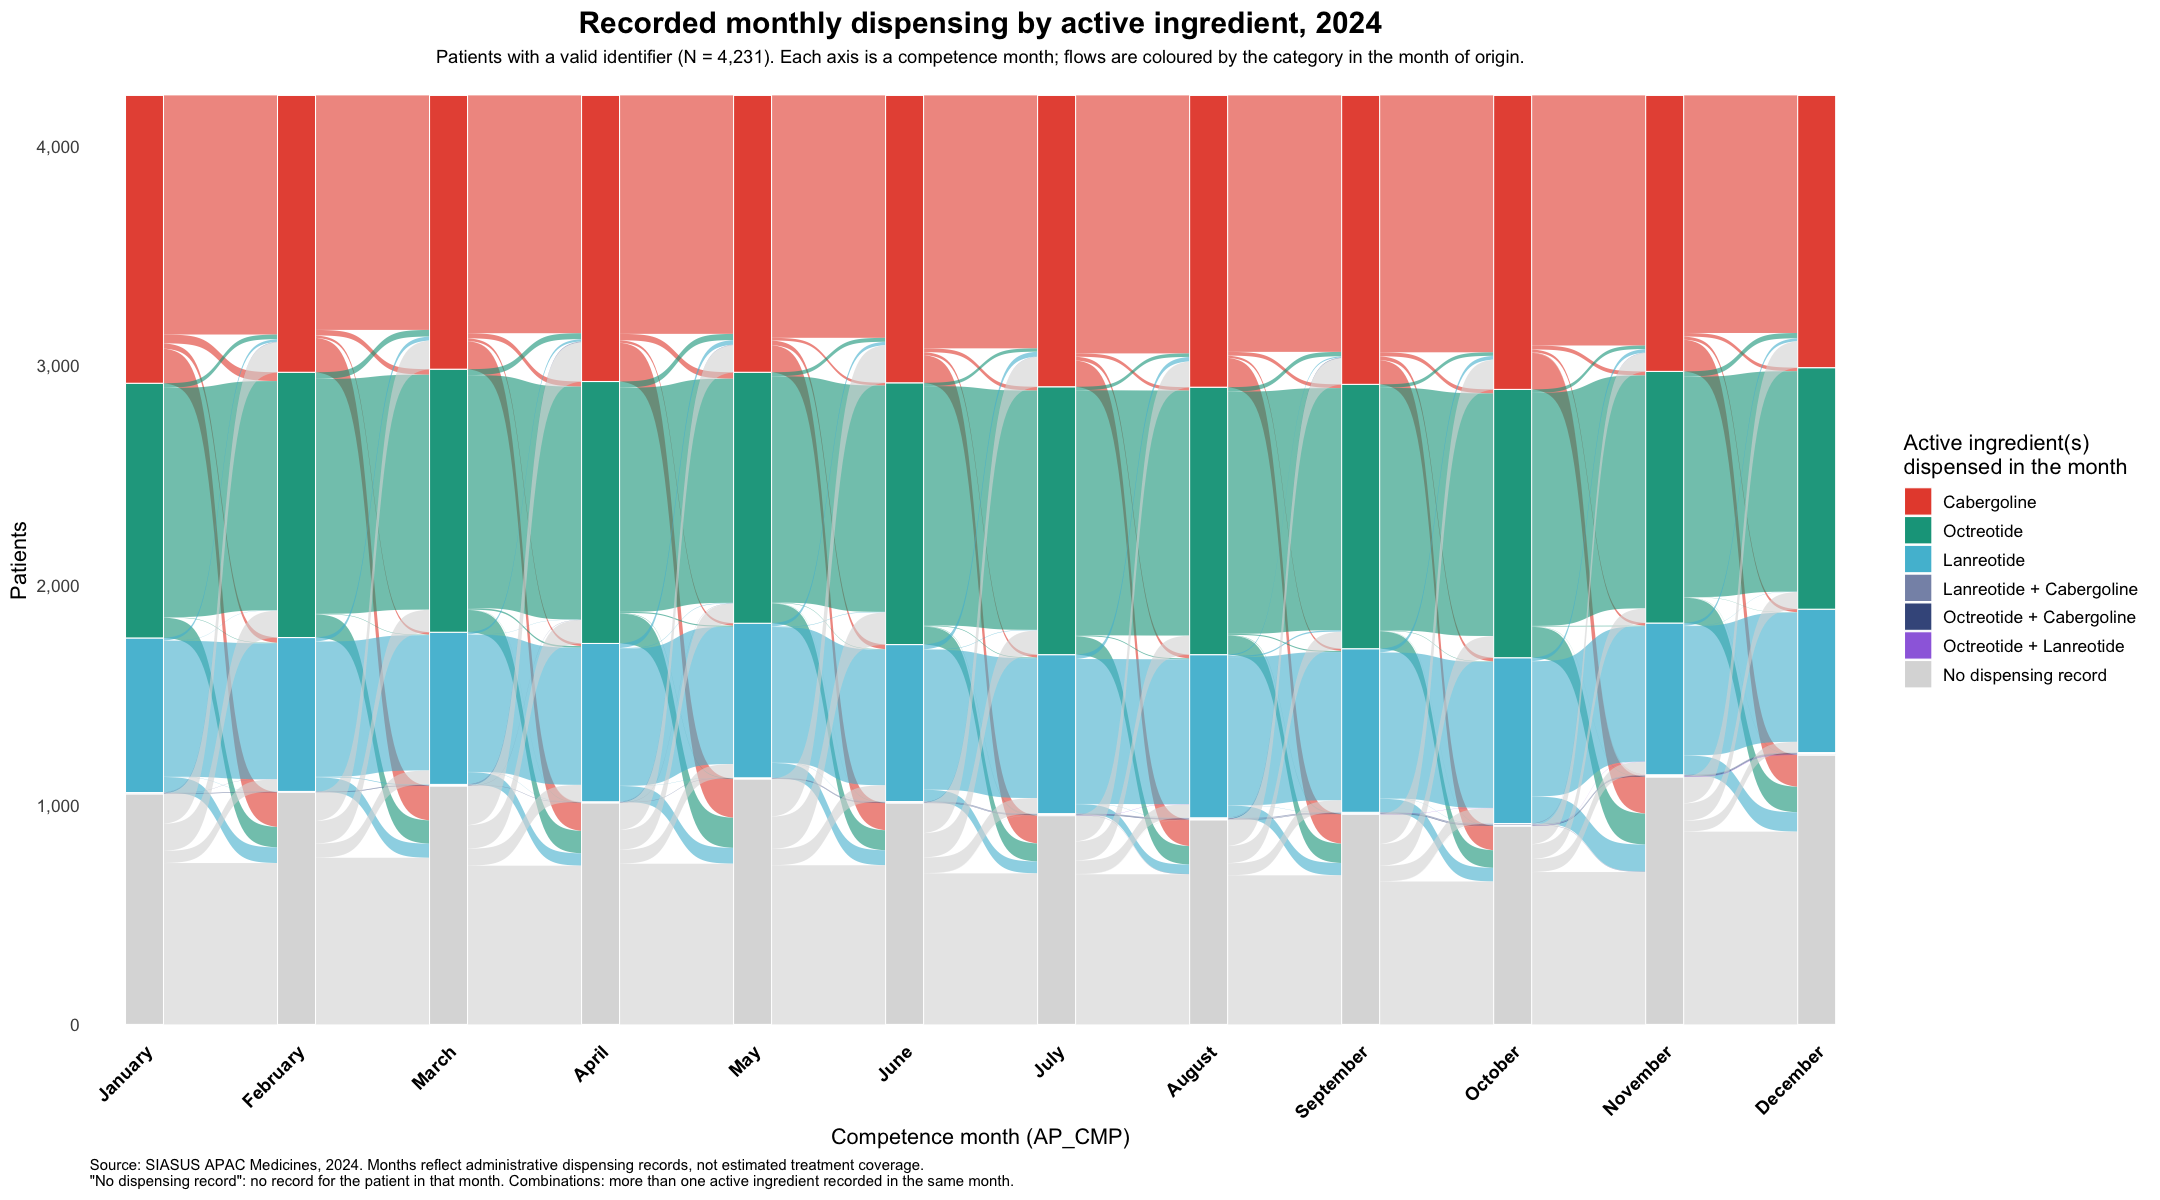

In [37]:
cat("=== 7.4.4 - FIGURA 2: DISPENSAÇÃO MENSAL REGISTRADA ===\n")
library(ggalluvial)

meses_en <- c("January", "February", "March", "April", "May", "June",
              "July", "August", "September", "October", "November", "December")
ordem_principio <- c("Octreotide", "Lanreotide", "Cabergoline")

# 1. Categoria por paciente-mês: conjunto de princípios ativos dispensados no mês
paciente_mes_categoria <- dados_unificados %>%
  mutate(mes_num = as.integer(format(AP_CMP, "%m")), principio = principio_ativo(AP_PRIPAL)) %>%
  distinct(AP_CNSPCN, mes_num, principio) %>%
  mutate(principio = factor(principio, levels = ordem_principio)) %>%
  arrange(principio) %>%
  group_by(AP_CNSPCN, mes_num) %>%
  summarise(categoria = paste(as.character(principio), collapse = " + "), .groups = "drop")

# 2. Grade completa paciente x 12 meses; meses sem registro = "No dispensing record"
grade_paciente_mes <- tidyr::expand_grid(AP_CNSPCN = unique(dados_unificados$AP_CNSPCN), mes_num = 1:12) %>%
  left_join(paciente_mes_categoria, by = c("AP_CNSPCN", "mes_num")) %>%
  mutate(categoria = coalesce(categoria, "No dispensing record"))

n_pacientes_fig2 <- n_distinct(grade_paciente_mes$AP_CNSPCN)
stopifnot(n_pacientes_fig2 == n_distinct(dados_unificados$AP_CNSPCN))

niveis_categoria <- grade_paciente_mes %>%
  filter(categoria != "No dispensing record") %>%
  count(categoria, sort = TRUE) %>%
  pull(categoria)
niveis_categoria <- c(niveis_categoria, "No dispensing record")

# 3. Tabela de dados da figura: pacientes por categoria e mês
tabela_fig2_mensal <- grade_paciente_mes %>%
  count(mes = meses_en[mes_num], mes_num, categoria) %>%
  arrange(mes_num) %>%
  select(-mes_num) %>%
  pivot_wider(names_from = mes, values_from = n, values_fill = 0) %>%
  arrange(factor(categoria, levels = niveis_categoria))
print(tabela_fig2_mensal)

# Pacientes-mês com mais de um princípio ativo (antes descartados por first())
pacientes_mes_combinacao <- paciente_mes_categoria %>% filter(str_detect(categoria, "\\+"))
cat("Pacientes-mês com combinação de princípios ativos:", nrow(pacientes_mes_combinacao),
    "| pacientes:", n_distinct(pacientes_mes_combinacao$AP_CNSPCN), "\n")

# Transições entre meses consecutivos
transicoes_fig2 <- grade_paciente_mes %>%
  arrange(AP_CNSPCN, mes_num) %>%
  group_by(AP_CNSPCN) %>%
  mutate(categoria_seguinte = lead(categoria), mes_seguinte = lead(mes_num)) %>%
  ungroup() %>%
  filter(!is.na(categoria_seguinte)) %>%
  count(mes_origem = meses_en[mes_num], mes_destino = meses_en[mes_seguinte],
        categoria_origem = categoria, categoria_destino = categoria_seguinte, name = "pacientes")

exportar_xlsx(list("pacientes_por_mes_categoria" = tabela_fig2_mensal,
                          "transicoes_mes_a_mes" = transicoes_fig2),
                     gerar_nome_arquivo("figura2_dispensacao_mensal_dados"))

# 4. Formato lodes, agregando trajetórias idênticas (peso = nº de pacientes)
trajetorias <- grade_paciente_mes %>%
  mutate(mes = meses_en[mes_num]) %>%
  select(AP_CNSPCN, mes, categoria) %>%
  pivot_wider(names_from = mes, values_from = categoria) %>%
  count(across(all_of(meses_en)), name = "pacientes") %>%
  mutate(trajetoria = row_number())

lodes_fig2 <- trajetorias %>%
  pivot_longer(all_of(meses_en), names_to = "mes", values_to = "categoria") %>%
  mutate(mes = factor(mes, levels = meses_en),
         categoria = factor(categoria, levels = niveis_categoria))

cores_categoria <- c(
  "Octreotide" = "#00A087", "Lanreotide" = "#4DBBD5", "Cabergoline" = "#E64B35",
  "Octreotide + Cabergoline" = "#3C5488", "Lanreotide + Cabergoline" = "#8491B4",
  "Octreotide + Lanreotide" = "#9C6ADE", "Octreotide + Lanreotide + Cabergoline" = "#7E6148",
  "No dispensing record" = "grey85"
)
cores_categoria <- cores_categoria[names(cores_categoria) %in% niveis_categoria]

p_alluvial_grupo <- ggplot(lodes_fig2,
                           aes(x = mes, stratum = categoria, alluvium = trajetoria, y = pacientes,
                               fill = categoria)) +
  geom_flow(aes.flow = "forward", alpha = 0.6, width = 1/4, curve_type = "sigmoid") +
  geom_stratum(width = 1/4, color = "white", linewidth = 0.3, alpha = 0.95) +
  scale_fill_manual(values = cores_categoria, breaks = niveis_categoria, name = "Active ingredient(s)\ndispensed in the month") +
  scale_x_discrete(expand = c(0.03, 0.03)) +
  scale_y_continuous(labels = scales::label_comma(), expand = c(0.01, 0.01)) +
  labs(
    title = "Recorded monthly dispensing by active ingredient, 2024",
    subtitle = paste0("Patients with a valid identifier (N = ", format(n_pacientes_fig2, big.mark = ","),
                      "). Each axis is a competence month; flows are coloured by the category in the month of origin."),
    x = "Competence month (AP_CMP)",
    y = "Patients",
    caption = paste0("Source: SIASUS APAC Medicines, 2024. Months reflect administrative dispensing records, not estimated treatment coverage.\n",
                     "\"No dispensing record\": no record for the patient in that month. Combinations: more than one active ingredient recorded in the same month.")
  ) +
  theme_minimal(base_size = 13) +
  theme(
    plot.title = element_text(size = 18, face = "bold", hjust = 0.5),
    plot.subtitle = element_text(size = 11, hjust = 0.5, margin = margin(b = 12)),
    axis.text.x = element_text(angle = 45, hjust = 1, size = 11, face = "bold", color = "black"),
    panel.grid = element_blank(),
    legend.position = "right",
    plot.caption = element_text(size = 9, hjust = 0),
    plot.background = element_rect(fill = "white", color = NA),
    panel.background = element_rect(fill = "white", color = NA)
  )

options(repr.plot.width = 18, repr.plot.height = 10)
print(p_alluvial_grupo)

tryCatch({
  caminho_grafico_grupo <- gerar_nome_png("figura2_dispensacao_mensal_registrada")
  ggsave(filename = caminho_grafico_grupo, plot = p_alluvial_grupo,
         width = 18, height = 10, units = "in", dpi = 300)
  cat("✅ Figura 2 salva em:", caminho_grafico_grupo, "\n")
}, error = function(e) {
  cat("❌ ERRO ao salvar a Figura 2:\n")
  print(e)
})


## 8. Usuários que não retornaram ao uso do medicamento

### 8.1 Uso de medicamentos por mês

In [38]:
# Gerar tabela de AP_CNS únicos por medicamento e por mês
library(dplyr)
library(tidyr)
library(stringr)
library(lubridate)

# Supondo que dados possui as colunas: "AP_CNSPCN", "mes", "med_nome"

# 1. Garantir que 'mes' está em formato Date e capturar o mês por extenso ordenadamente
# Aqui assumo que 'mes' já está em formato YYYY-MM ou Date. Se não, ajuste este processamento conforme o formato exato.
if (!inherits(dados$mes, "Date")) {
  # Tenta converter. Se falhar, pode ser necessário ajustar o formato.
  dados$mes <- as.Date(paste0(dados$mes, "-01"))
}

dados <- dados %>%
  mutate(
    mes_nome = str_to_sentence(format(mes, "%B")),
    mes_ano = format(mes, "%Y-%m")
  )

# 2. Tabela base: quantidade de pacientes únicos por med_nome e mês
tab_base <- dados %>%
  group_by(med_nome, mes_ano, mes_nome) %>%
  summarise(qtd_pacientes = n_distinct(AP_CNSPCN), .groups = 'drop')

# 3. Quantidade total por mes (todos medicamentos juntos)
todos_meds_mes <- dados %>%
  group_by(mes_ano, mes_nome) %>%
  summarise(qtd_pacientes = n_distinct(AP_CNSPCN), .groups = 'drop') %>%
  mutate(med_nome = "TOTAL") %>%
  select(med_nome, everything())

tab_base <- bind_rows(tab_base, todos_meds_mes)

# 4. Calcular total de pacientes únicos por med_nome para cada mês (para percentual)
percentual_tab <- tab_base %>%
  filter(med_nome != "TOTAL") %>%
  group_by(med_nome) %>%
  mutate(total_med = sum(qtd_pacientes)) %>%
  ungroup() %>%
  mutate(percentual = round(qtd_pacientes / total_med * 100, 2))

# 5. Pivotar tabela para formato requisitado: uma linha por med_nome, colunas para cada mes_frequencia e mes_percentual
# Precisamos garantir ordenação correta dos meses
ordem_meses <- percentual_tab %>%
  distinct(mes_ano, mes_nome) %>%
  arrange(mes_ano) %>%
  mutate(mes_col = paste0("mes_", str_to_lower(mes_nome)))

pivot_frequencia <- percentual_tab %>%
  mutate(mes_col_f = paste0("mes_", str_to_lower(mes_nome), "_frequencia"),
         mes_col_p = paste0("mes_", str_to_lower(mes_nome), "_percentual")) %>%
  select(med_nome, mes_ano, qtd_pacientes, percentual, mes_col_f, mes_col_p)

# Monta tabela wide para frequencia e percentual juntos
tabela_final <- NULL
for (i in seq_along(ordem_meses$mes_ano)) {
  mesf <- ordem_meses$mes_nome[i]
  colf <- paste0("mes_", str_to_lower(mesf), "_frequencia")
  colp <- paste0("mes_", str_to_lower(mesf), "_percentual")
  
  # Para o mês corrente e todas drogas
  temp <- pivot_frequencia %>%
    filter(mes_ano == ordem_meses$mes_ano[i]) %>%
    select(med_nome, qtd_pacientes, percentual)
  names(temp)[2:3] <- c(colf, colp)
  if (is.null(tabela_final)) {
    tabela_final <- temp
  } else {
    tabela_final <- full_join(tabela_final, temp, by = "med_nome")
  }
}
# Substituir NA por 0
tabela_final[is.na(tabela_final)] <- 0

# 6. Calcular quem NÃO recebeu medicamento no mês (ou seja, estava mês passado, não está no atual) — para cada mês >=2
meses_ordenados <- ordem_meses$mes_ano

df_nao_recebeu <- list()
for (idx in 2:length(meses_ordenados)) {
  mes_atual <- meses_ordenados[idx]
  mes_ant <- meses_ordenados[idx - 1]
  
  # Todos pacientes do mês anterior
  pac_antes <- dados %>%
    filter(mes_ano == mes_ant) %>%
    distinct(AP_CNSPCN)
  # Todos pacientes do mês atual
  pac_agora <- dados %>%
    filter(mes_ano == mes_atual) %>%
    distinct(AP_CNSPCN)
  # Pacientes que saíram
  perdeu <- setdiff(pac_antes$AP_CNSPCN, pac_agora$AP_CNSPCN)
  freq_perdeu <- length(perdeu)
  
  # Total do mês anterior (referência para percentual)
  total_antes <- nrow(pac_antes)
  perc_perdeu <- ifelse(total_antes == 0, 0, round(freq_perdeu / total_antes * 100, 2))
  
  # Nome da coluna
  colfrequencia <- paste0("mes_", str_to_lower(ordem_meses$mes_nome[idx]), "_frequencia")
  colpercentual <- paste0("mes_", str_to_lower(ordem_meses$mes_nome[idx]), "_percentual")
  
  df_nao_recebeu[[idx]] <- data.frame(
    med_nome = "nao recebeu medicamento no mês",
    tempf = freq_perdeu,
    tempp = perc_perdeu
  )
  names(df_nao_recebeu[[idx]]) <- c("med_nome", colfrequencia, colpercentual)
}

# Monta linha final "nao recebeu medicamento no mês"
linha_nao_recebeu <- Reduce(function(x, y) full_join(x, y, by = "med_nome"), df_nao_recebeu[2:length(df_nao_recebeu)])

# Preenche os meses iniciais (onde não há "anterior") com NA ou 0
for (i in seq_along(ordem_meses$mes_nome)) {
  colfrequencia <- paste0("mes_", str_to_lower(ordem_meses$mes_nome[i]), "_frequencia")
  colpercentual <- paste0("mes_", str_to_lower(ordem_meses$mes_nome[i]), "_percentual")
  if (!(colfrequencia %in% names(linha_nao_recebeu))) {
    linha_nao_recebeu[[colfrequencia]] <- NA
    linha_nao_recebeu[[colpercentual]] <- NA
  }
}

# Reordenar colunas para bater com tabela_final (frequencia, percentual...) — manter a mesmíssima ordem das colunas
linha_nao_recebeu <- linha_nao_recebeu[, names(tabela_final)]

# Adiciona a linha à tabela
tabela_final_saida <- bind_rows(tabela_final, linha_nao_recebeu)

# Exibir tabela final
print(tabela_final_saida)

# Se desejar salvar:
data_atual <- format(Sys.Date(), "%Y%m%d")
nome_arquivo <- paste0(pasta_resultados, data_atual, "_unique_users_by_medication_month.csv")
tryCatch({
  write.csv(traduzir_df(tabela_final_saida), nome_arquivo, row.names = FALSE, na = "")
  cat("\n✅ Tabela salva em:", nome_arquivo, "\n")
}, error = function(e) {
  cat("\n❌ Erro ao salvar a tabela:", e$message, "\n")
})

# A tibble: 8 × 25
  med_nome  mes_january_frequencia mes_january_percentual mes_february_frequen…¹
  <chr>                      <int>                  <dbl>                  <int>
1 Cabergol…                   1317                   8.45                   1265
2 LANREOTI…                     24                   7.1                      28
3 Lan120                       492                   8.31                    489
4 Lan90                        191                   8.11                    187
5 OCTREOTI…                     54                   8.08                     57
6 Oct20                        540                   8.33                    543
7 Oct30                        573                   8.06                    611
8 nao rece…                     NA                  NA                       322
# ℹ abbreviated name: ¹​mes_february_frequencia
# ℹ 21 more variables: mes_february_percentual <dbl>,
#   mes_march_frequencia <int>, mes_march_percentual <dbl>,
#   mes_a

### 8.2 Abandono do tratamento
- Usuários que não usaram o medicamento >= 6 meses

In [39]:
library(lubridate)
library(writexl)

# 1. Calcular abandono considerando AP_CNSPCN que usaram em qualquer mês do ano:

# Define os meses/ano presentes nos dados
unico_ano <- unique(year(dados$mes))
if(length(unico_ano) > 1){
  warning("Mais de um ano encontrado nos dados. Considerando apenas o primeiro:", unico_ano[1])
}
ano_referencia <- unico_ano[1]

# Identifica todo AP_CNSPCN + med_nome que usaram QUALQUER mês do ANO
dados_ano <- dados %>%
  filter(year(mes) == ano_referencia)

# Usuários distintos por medicamento ao longo do ano
usuarios_ano <- dados_ano %>%
  group_by(med_nome) %>%
  summarize(usuarios_frequencia_ano = n_distinct(AP_CNSPCN))

# Último mês do ano no dataset
ultimo_mes_ano <- max(dados_ano$mes, na.rm = TRUE)

# AP_CNSPCN+med_nome: quando foi a última dispensação no ANO?
ultimo_uso_ano <- dados_ano %>%
  group_by(AP_CNSPCN, med_nome) %>%
  summarize(ultimo_mes_uso = max(mes), primeiro_mes_uso = min(mes), .groups="drop")

# Considera abandono se último uso foi 5 ou mais meses antes do fim do ano
limite_abandono_ano <- ultimo_mes_ano %m-% months(5)

abandono_ano <- ultimo_uso_ano %>%
  filter(ultimo_mes_uso <= limite_abandono_ano)

# Contagem de abandono por med_nome
abandono_ano_contagem <- abandono_ano %>%
  group_by(med_nome) %>%
  summarize(usuarios_abandono_frequencia = n_distinct(AP_CNSPCN))

# Construir tabela abandono anual
tabela_abandono_anual <- usuarios_ano %>%
  left_join(abandono_ano_contagem, by = "med_nome") %>%
  mutate(
    usuarios_abandono_frequencia = ifelse(is.na(usuarios_abandono_frequencia), 0, usuarios_abandono_frequencia),
    usuarios_abandono_percentual = round(usuarios_abandono_frequencia / usuarios_frequencia_ano * 100, 2)
  ) %>%
  arrange(desc(usuarios_frequencia_ano))

# 2. Salvar o resultado no @resultados/ com formatação YYYYMMDD_acromegalia_abandono_anual.xlsx
data_hoje <- format(Sys.Date(), "%Y%m%d")
nome_arquivo_abandono <- paste0(pasta_resultados, data_hoje, "_acromegaly_annual_discontinuation.xlsx")

tryCatch({
  write_xlsx(traduzir_df(tabela_abandono_anual), nome_arquivo_abandono)
  cat("\n✅ Tabela de abandono anual salva em:", nome_arquivo_abandono, "\n")
}, error = function(e){
  cat("\n❌ Não foi possível salvar a planilha:", e$message, "\n")
})

tabela_abandono_anual


✅ Tabela de abandono anual salva em: ../resultados/third_review/20261013_acromegaly_annual_discontinuation.xlsx 


med_nome,usuarios_frequencia_ano,usuarios_abandono_frequencia,usuarios_abandono_percentual
<chr>,<int>,<int>,<dbl>
Cabergolina,2021,336,16.63
Oct30,900,157,17.44
Lan120,814,157,19.29
Oct20,814,130,15.97
Lan90,321,54,16.82
OCTREOTIDA,87,19,21.84
LANREOTIDA,49,7,14.29


## 9. Fluxograma de Construção da Base de Dados (SIA PA + SIA AM)

**Terceira revisão (itens 1c, 5a, 5b, 5d).** O fluxograma distingue registros, chaves (autorização-competência-processamento), autorizações e pacientes; mostra a agregação do PA antes da ligação, a ligação 1:0..1 em nível de autorização, o filtro de 2024 e a exclusão de registros sem identificador do paciente. Nenhuma fonte é rotulada como "deduplicada": a deduplicação em nível de paciente (CNS) ocorre só no final.


=== 9. FLUXOGRAMA DE CONSTRUÇÃO DA BASE (SIA PA + SIA AM) ===
# A tibble: 20 × 2
   etapa                                                                   valor
   <chr>                                                                   <int>
 1 1a. APAC Medicines (AM) - registros brutos (1 por autorização-competên… 84042
 2 1b. AM - autorizações únicas                                            39254
 3 1c. Outpatient Production (PA) - linhas brutas                          97280
 4 1d. PA - autorizações únicas                                            30896
 5 2. PA agregado para 1 linha por chave (autorização-competência-process… 75377
 6 3a. Ligação 1:0..1 - registros AM com chave PA correspondente           74764
 7 3b. Ligação - registros AM sem chave PA correspondente (mantidos)        9278
 8 3c. Chaves PA sem registro AM correspondente (excluídas)                  613
 9 3d. Autorizações PA sem nenhuma correspondência no AM (excluídas)         489
10 3e. Base ligada - registr

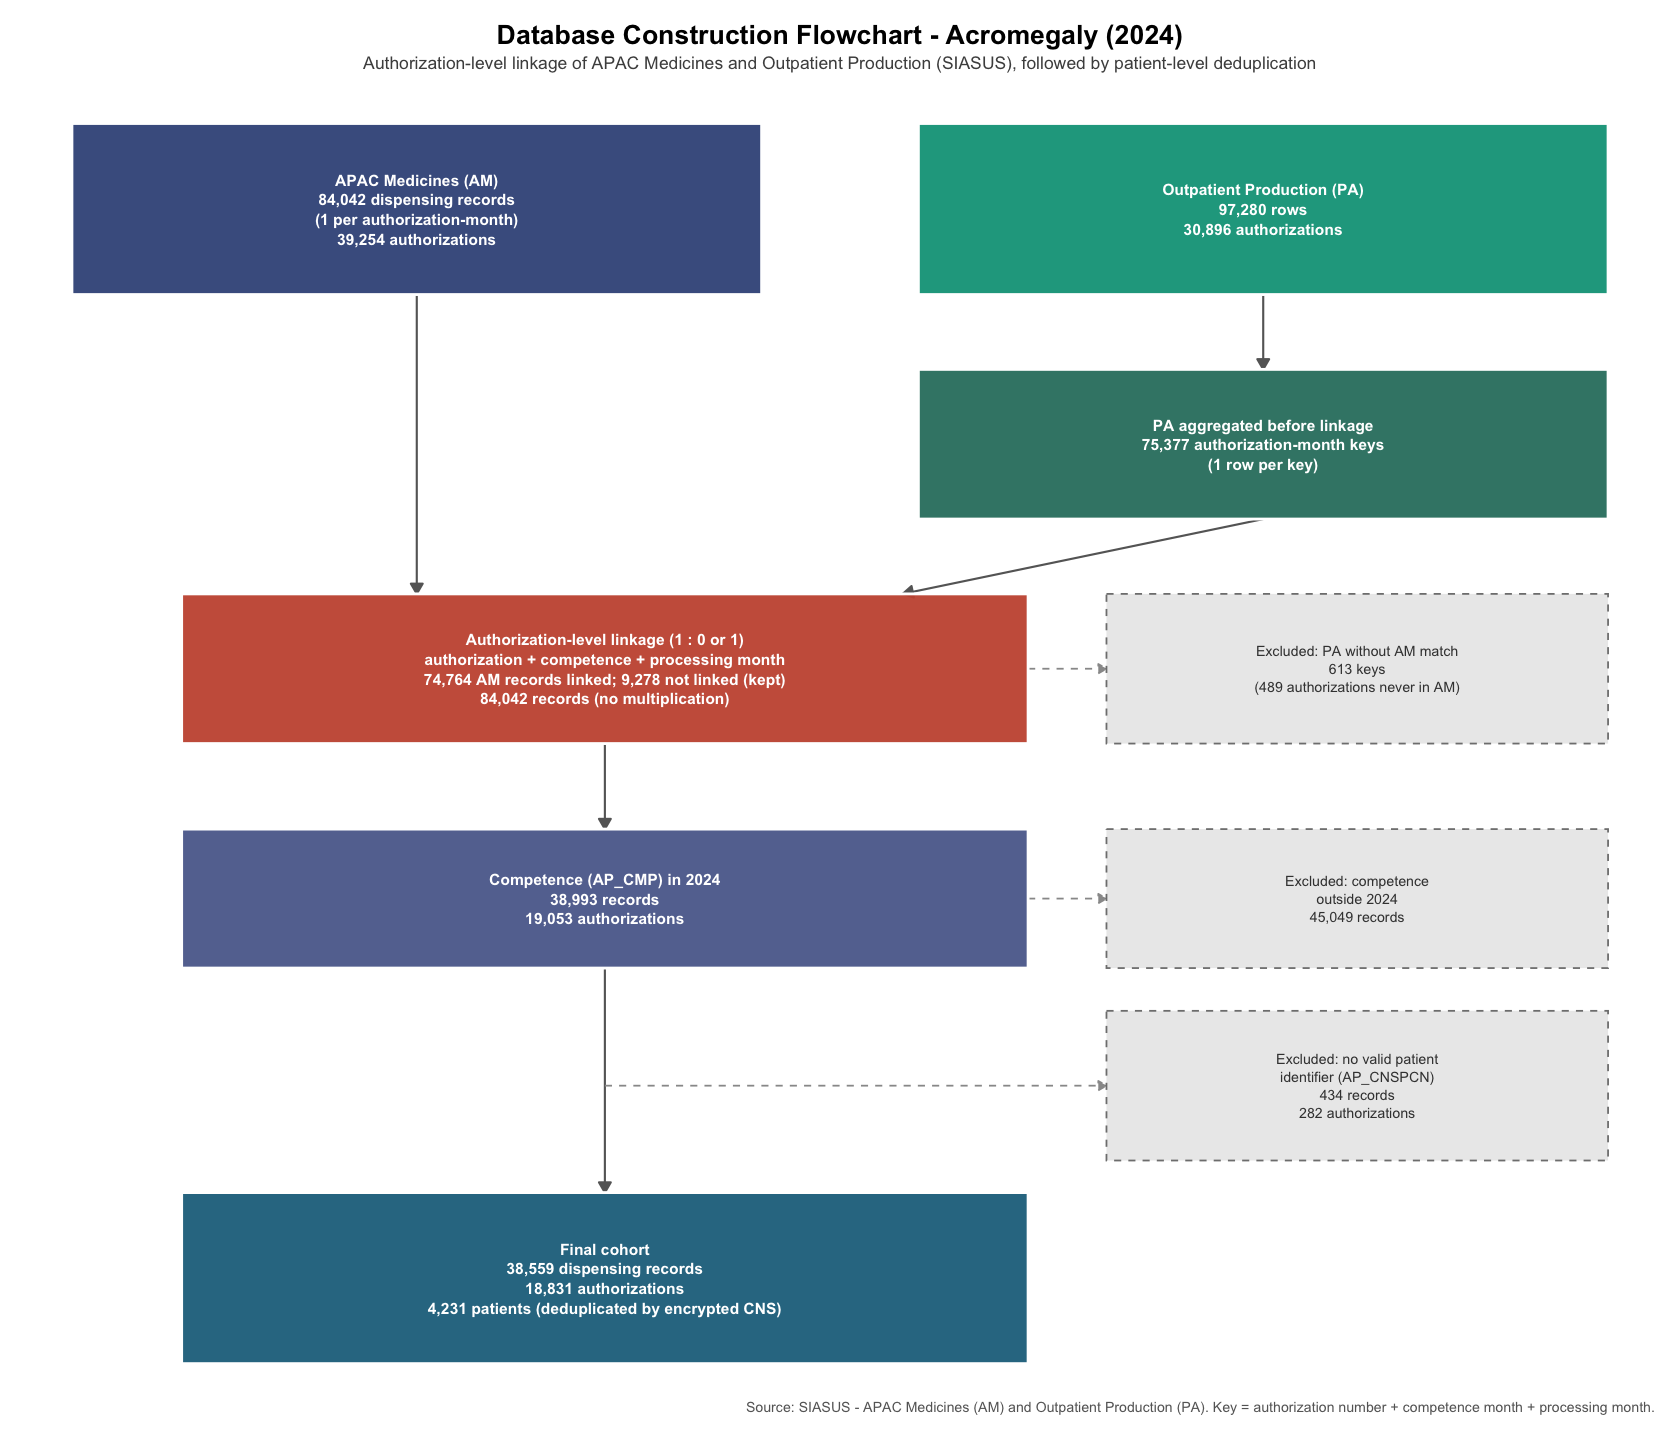

In [40]:
cat("=== 9. FLUXOGRAMA DE CONSTRUÇÃO DA BASE (SIA PA + SIA AM) ===\n")
library(ggplot2)

fmt <- function(x) format(x, big.mark = ",", decimal.mark = ".", scientific = FALSE)

n_am_registros <- nrow(data_am)
n_am_autoriz <- n_distinct(data_am$AP_AUTORIZ)
n_am_pacientes <- n_distinct(data_am$AP_CNSPCN, na.rm = TRUE)
n_pa_linhas <- nrow(data_pa)
n_pa_chaves <- nrow(data_pa_chave)
n_pa_autoriz <- n_distinct(data_pa$PA_AUTORIZ)
n_ligados <- n_registros_vinculados
n_nao_ligados <- n_am_registros - n_ligados
n_pa_chaves_sem_am <- nrow(chaves_pa_sem_am)
n_pa_autoriz_sem_am <- length(autoriz_pa_sem_am)
n_fora_2024 <- n_am_registros - nrow(dados_2024_todos)
n_2024_registros <- nrow(dados_2024_todos)
n_2024_autoriz <- n_distinct(dados_2024_todos$AP_AUTORIZ)
n_final_registros <- nrow(dados_unificados)
n_final_autoriz <- n_distinct(dados_unificados$AP_AUTORIZ)
n_final_pacientes <- n_distinct(dados_unificados$AP_CNSPCN)
n_final_ligados <- sum(dados_unificados$vinculado_pa)

tabela_fluxo <- tibble::tibble(
  etapa = c(
    "1a. APAC Medicines (AM) - registros brutos (1 por autorização-competência-processamento)",
    "1b. AM - autorizações únicas",
    "1c. Outpatient Production (PA) - linhas brutas",
    "1d. PA - autorizações únicas",
    "2. PA agregado para 1 linha por chave (autorização-competência-processamento)",
    "3a. Ligação 1:0..1 - registros AM com chave PA correspondente",
    "3b. Ligação - registros AM sem chave PA correspondente (mantidos)",
    "3c. Chaves PA sem registro AM correspondente (excluídas)",
    "3d. Autorizações PA sem nenhuma correspondência no AM (excluídas)",
    "3e. Base ligada - registros (igual ao AM)",
    "4a. Registros com competência fora de 2024 (excluídos)",
    "4b. Registros com competência 2024",
    "4c. Autorizações com competência 2024",
    "5a. Registros sem identificador do paciente (excluídos)",
    "5b. Autorizações com registro sem identificador do paciente",
    "5c. Autorizações excluídas por completo",
    "6a. Coorte final - registros de dispensação",
    "6b. Coorte final - registros com correspondência no PA",
    "6c. Coorte final - autorizações",
    "6d. Coorte final - pacientes únicos (deduplicação pelo CNS)"
  ),
  valor = c(n_am_registros, n_am_autoriz, n_pa_linhas, n_pa_autoriz, n_pa_chaves,
            n_ligados, n_nao_ligados, n_pa_chaves_sem_am, n_pa_autoriz_sem_am, n_am_registros,
            n_fora_2024, n_2024_registros, n_2024_autoriz,
            registros_sem_cns, autoriz_sem_cns, autoriz_sem_cns_total,
            n_final_registros, n_final_ligados, n_final_autoriz, n_final_pacientes)
)
print(tabela_fluxo, n = Inf)
exportar_xlsx(tabela_fluxo, gerar_nome_arquivo("fluxograma_uniao_dados"))

caixas <- tibble::tibble(
  xmin = c(0.3, 5.7, 5.7, 1.0, 1.0, 1.0),
  xmax = c(4.7, 10.1, 10.1, 6.4, 6.4, 6.4),
  ymin = c(10.4, 10.4, 8.3, 6.2, 4.1, 0.4),
  ymax = c(12.0, 12.0, 9.7, 7.6, 5.4, 2.0),
  fill = c("#3C5488", "#00A087", "#2E7D6E", "#C8553D", "#5B6A9A", "#1F6F8B"),
  label = c(
    paste0("APAC Medicines (AM)\n", fmt(n_am_registros), " dispensing records\n(1 per authorization-month)\n",
           fmt(n_am_autoriz), " authorizations"),
    paste0("Outpatient Production (PA)\n", fmt(n_pa_linhas), " rows\n", fmt(n_pa_autoriz), " authorizations"),
    paste0("PA aggregated before linkage\n", fmt(n_pa_chaves), " authorization-month keys\n(1 row per key)"),
    paste0("Authorization-level linkage (1 : 0 or 1)\nauthorization + competence + processing month\n",
           fmt(n_ligados), " AM records linked; ", fmt(n_nao_ligados), " not linked (kept)\n",
           fmt(n_am_registros), " records (no multiplication)"),
    paste0("Competence (AP_CMP) in 2024\n", fmt(n_2024_registros), " records\n", fmt(n_2024_autoriz), " authorizations"),
    paste0("Final cohort\n", fmt(n_final_registros), " dispensing records\n", fmt(n_final_autoriz),
           " authorizations\n", fmt(n_final_pacientes), " patients (deduplicated by encrypted CNS)")
  )
)

excluidos <- tibble::tibble(
  xmin = c(6.9, 6.9, 6.9), xmax = c(10.1, 10.1, 10.1),
  ymin = c(6.2, 4.1, 2.3), ymax = c(7.6, 5.4, 3.7),
  label = c(
    paste0("Excluded: PA without AM match\n", fmt(n_pa_chaves_sem_am), " keys\n(",
           fmt(n_pa_autoriz_sem_am), " authorizations never in AM)"),
    paste0("Excluded: competence\noutside 2024\n", fmt(n_fora_2024), " records"),
    paste0("Excluded: no valid patient\nidentifier (AP_CNSPCN)\n", fmt(registros_sem_cns), " records\n",
           fmt(autoriz_sem_cns), " authorizations")
  )
)

setas <- tibble::tibble(
  x = c(2.5, 7.9, 7.9, 3.7, 3.7), xend = c(2.5, 7.9, 5.6, 3.7, 3.7),
  y = c(10.4, 10.4, 8.3, 6.2, 4.1), yend = c(7.6, 9.7, 7.6, 5.4, 2.0)
)
setas_excl <- tibble::tibble(x = c(6.4, 6.4, 3.7), xend = c(6.9, 6.9, 6.9),
                             y = c(6.9, 4.75, 3.0), yend = c(6.9, 4.75, 3.0))

p_fluxo <- ggplot() +
  geom_segment(data = setas, aes(x = x, y = y, xend = xend, yend = yend),
               arrow = arrow(length = unit(0.25, "cm"), type = "closed"), color = "gray40", linewidth = 0.6) +
  geom_segment(data = setas_excl, aes(x = x, y = y, xend = xend, yend = yend),
               arrow = arrow(length = unit(0.2, "cm"), type = "closed"), color = "gray60",
               linewidth = 0.5, linetype = "dashed") +
  geom_rect(data = caixas, aes(xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax, fill = fill),
            color = "white", linewidth = 0.8, alpha = 0.95) +
  geom_text(data = caixas, aes(x = (xmin + xmax) / 2, y = (ymin + ymax) / 2, label = label),
            color = "white", size = 3.3, fontface = "bold", lineheight = 1.05) +
  geom_rect(data = excluidos, aes(xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax),
            fill = "grey92", color = "grey50", linewidth = 0.5, linetype = "dashed") +
  geom_text(data = excluidos, aes(x = (xmin + xmax) / 2, y = (ymin + ymax) / 2, label = label),
            color = "grey25", size = 3.0, lineheight = 1.05) +
  scale_fill_identity() +
  scale_x_continuous(limits = c(0, 10.4), expand = c(0, 0)) +
  scale_y_continuous(limits = c(0.2, 12.3), expand = c(0, 0)) +
  labs(
    title = "Database Construction Flowchart - Acromegaly (2024)",
    subtitle = "Authorization-level linkage of APAC Medicines and Outpatient Production (SIASUS), followed by patient-level deduplication",
    caption = "Source: SIASUS - APAC Medicines (AM) and Outpatient Production (PA). Key = authorization number + competence month + processing month."
  ) +
  theme_void(base_size = 12) +
  theme(
    plot.title = element_text(face = "bold", size = 16, hjust = 0.5, margin = margin(b = 4)),
    plot.subtitle = element_text(size = 10.5, hjust = 0.5, margin = margin(b = 12), color = "grey30"),
    plot.caption = element_text(size = 8.5, hjust = 1, margin = margin(t = 10), color = "grey40"),
    plot.background = element_rect(fill = "white", color = NA),
    panel.background = element_rect(fill = "white", color = NA),
    plot.margin = margin(15, 15, 15, 15)
  )

options(repr.plot.width = 14, repr.plot.height = 12)
print(p_fluxo)

tryCatch({
  caminho_fluxo <- gerar_nome_png("fluxograma_uniao_dados")
  ggsave(filename = caminho_fluxo, plot = p_fluxo, device = "png", width = 14, height = 12, units = "in", dpi = 300)
  cat("✅ Fluxograma salvo em:", caminho_fluxo, "\n")
}, error = function(e) {
  cat("❌ ERRO ao salvar o fluxograma:\n")
  print(e)
})
